In [ ]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os

ZIP_PATH = "gwa_t_12_fastStorage.zip"

print("Libraries imported successfully!")

In [ ]:

zip_file = zipfile.ZipFile(ZIP_PATH)

files = [
    f for f in zip_file.namelist()
    if f.endswith(".csv")
]

print("Total VM files:", len(files))
print("\nFirst 10 files:")

for f in files[:10]:
    print(f)

In [ ]:
sample_file = "fastStorage/2013-8/1.csv"

df = pd.read_csv(
    zip_file.open(sample_file),
    sep=";",
    skipinitialspace=True
)

df.columns = df.columns.str.strip()

print("Shape:", df.shape)

display(df.head())
print(df.info())

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

print("\nDuplicate timestamps:")
print(df["Timestamp [ms]"].duplicated().sum())

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp [ms]"],
    df["CPU usage [%]"]
)

plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization (%)")
plt.title("CPU Utilization of VM 1")

plt.grid(True)
plt.show()

In [ ]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Path to the downloaded trace archive
ZIP_PATH = "gwa_t_12_fastStorage.zip"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP file not found. Place it in the same folder as this notebook."
    )

# Open the archive without extracting all the files
zip_file = zipfile.ZipFile(ZIP_PATH)

# Get all VM CSV files
vm_files = [
    name for name in zip_file.namelist()
    if name.lower().endswith(".csv")
]

print("Total VM trace files:", len(vm_files))

print("\nSample VM files:")
for name in vm_files[:5]:
    print(name)

In [ ]:
# Read one VM file to inspect its timestamp values
sample = pd.read_csv(
    zip_file.open(vm_files[0]),
    sep=";",
    skipinitialspace=True
)

sample.columns = sample.columns.str.strip()

# Convert timestamps to numeric values
timestamp_sample = pd.to_numeric(
    sample["Timestamp [ms]"],
    errors="coerce"
).dropna()

if timestamp_sample.empty:
    raise ValueError("No valid timestamps found in the sample file.")

# Detect whether timestamps are in seconds or milliseconds
timestamp_median = timestamp_sample.median()

TIMESTAMP_UNIT = "ms" if timestamp_median > 1e12 else "s"

print("Sample VM file:", vm_files[0])
print("Number of records:", len(sample))
print("Detected timestamp unit:", TIMESTAMP_UNIT)

print("\nDataset columns:")
print(sample.columns.tolist())

In [ ]:
# Metrics that will be aggregated across all VMs
METRICS = [
    "CPU capacity provisioned [MHZ]",
    "CPU usage [MHZ]",
    "Memory capacity provisioned [KB]",
    "Memory usage [KB]",
    "Disk read throughput [KB/s]",
    "Disk write throughput [KB/s]",
    "Network received throughput [KB/s]",
    "Network transmitted throughput [KB/s]"
]

# Check that the required columns exist
required_columns = ["Timestamp [ms]"] + METRICS

missing_columns = [
    column for column in required_columns
    if column not in sample.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Five-minute aggregation interval
INTERVAL_SECONDS = 300

# Create names for the fleet-level measurements
sum_columns = [
    f"fleet_{column}" for column in METRICS
]

count_columns = [
    f"{column}_vm_count" for column in METRICS
]

# Initialize the fleet dataset
fleet_columns = (
    sum_columns
    + count_columns
    + ["observed_vm_count", "active_vm_count"]
)

fleet_data = pd.DataFrame(columns=fleet_columns, dtype="float64")

processed_files = 0
failed_files = []

print("Aggregation interval:", INTERVAL_SECONDS, "seconds")
print("Metrics selected:", len(METRICS))

In [ ]:
for file_name in vm_files:

    try:
        # Read the current VM trace
        vm = pd.read_csv(
            zip_file.open(file_name),
            sep=";",
            skipinitialspace=True
        )

        vm.columns = vm.columns.str.strip()

        # Convert the timestamp column into numeric values
        timestamp = pd.to_numeric(
            vm["Timestamp [ms]"],
            errors="coerce"
        )

        # Convert timestamps into seconds
        if TIMESTAMP_UNIT == "ms":
            timestamp_seconds = timestamp / 1000
        else:
            timestamp_seconds = timestamp

        # Remove records with invalid timestamps
        valid_time = timestamp_seconds.notna()

        vm = vm.loc[valid_time].copy()
        timestamp_seconds = timestamp_seconds.loc[valid_time]

        if vm.empty:
            continue

        # Assign each record to a five-minute time interval
        vm["time_bin"] = (
            np.floor(
                timestamp_seconds.to_numpy() / INTERVAL_SECONDS
            ) * INTERVAL_SECONDS
        ).astype("int64")

        # Convert workload measurements to numeric values
        for column in METRICS:
            vm[column] = pd.to_numeric(
                vm[column],
                errors="coerce"
            )

        # Calculate average measurements for this VM in each interval
        vm_means = vm.groupby("time_bin")[METRICS].mean()

        # Count whether the VM provided each metric in that interval
        vm_counts = vm.groupby("time_bin")[METRICS].count()

        vm_counts = vm_counts.gt(0).astype("int8")
        vm_counts.columns = count_columns

        # Rename measurement columns
        vm_means.columns = sum_columns

        vm_bins = pd.concat(
            [vm_means, vm_counts],
            axis=1
        )

        # Count VMs with provisioned CPU or memory capacity
        cpu_capacity = vm_bins[
            "fleet_CPU capacity provisioned [MHZ]"
        ]

        memory_capacity = vm_bins[
            "fleet_Memory capacity provisioned [KB]"
        ]

        vm_bins["active_vm_count"] = (
            (cpu_capacity.fillna(0) > 0) |
            (memory_capacity.fillna(0) > 0)
        ).astype("int8")

        # Count this VM once in each interval where it has a valid record
        vm_bins["observed_vm_count"] = 1

        # Add the current VM's measurements to the fleet totals
        fleet_data = fleet_data.add(
            vm_bins,
            fill_value=0
        )

        processed_files += 1

        # Display progress
        if processed_files % 100 == 0:
            print(
                f"Processed {processed_files:,} / "
                f"{len(vm_files):,} VM files"
            )

    except Exception as error:

        failed_files.append((file_name, str(error)))


print("\nVM processing completed.")

print("Successfully processed:", processed_files)
print("Files with errors:", len(failed_files))

if failed_files:
    print("\nFirst few processing errors:")
    for item in failed_files[:5]:
        print(item)

In [ ]:
# Sort the fleet measurements by timestamp
fleet_data = fleet_data.sort_index()

# Convert Unix timestamps into readable UTC datetime values
fleet_data.index = pd.to_datetime(
    fleet_data.index.astype("int64"),
    unit="s",
    utc=True
)

fleet_data.index.name = "timestamp"

# Rename columns to make them easier to use in later phases
rename_map = {
    "fleet_CPU capacity provisioned [MHZ]":
        "total_cpu_capacity_mhz",

    "fleet_CPU usage [MHZ]":
        "total_cpu_usage_mhz",

    "fleet_Memory capacity provisioned [KB]":
        "total_memory_capacity_kb",

    "fleet_Memory usage [KB]":
        "total_memory_usage_kb",

    "fleet_Disk read throughput [KB/s]":
        "total_disk_read_kbps",

    "fleet_Disk write throughput [KB/s]":
        "total_disk_write_kbps",

    "fleet_Network received throughput [KB/s]":
        "total_network_received_kbps",

    "fleet_Network transmitted throughput [KB/s]":
        "total_network_transmitted_kbps"
}

fleet_data = fleet_data.rename(columns=rename_map)

# Calculate trace-file observation coverage
total_vm_files = len(vm_files)

fleet_data["trace_vm_coverage_pct"] = (
    fleet_data["observed_vm_count"]
    / total_vm_files
) * 100

# Calculate fleet CPU utilization
fleet_data["cpu_utilization_pct"] = np.where(
    fleet_data["total_cpu_capacity_mhz"] > 0,

    (
        fleet_data["total_cpu_usage_mhz"]
        / fleet_data["total_cpu_capacity_mhz"]
    ) * 100,

    np.nan
)

# Calculate fleet memory utilization
fleet_data["memory_utilization_pct"] = np.where(
    fleet_data["total_memory_capacity_kb"] > 0,

    (
        fleet_data["total_memory_usage_kb"]
        / fleet_data["total_memory_capacity_kb"]
    ) * 100,

    np.nan
)

# Save the complete fleet-level dataset
OUTPUT_CSV = "fleet_workload_5min.csv"

fleet_data.to_csv(OUTPUT_CSV)

print("Fleet dataset successfully saved!")
print("Output file:", OUTPUT_CSV)

print("\nDataset dimensions:")
print(fleet_data.shape)

print("\nFirst five records:")
display(fleet_data.head())

In [ ]:
# Display basic statistics for all fleet-level measurements
print("Fleet workload descriptive statistics:")

display(
    fleet_data.describe().T
)

# Check missing values
print("\nMissing values in each column:")

display(
    fleet_data.isna().sum().to_frame(
        name="missing_values"
    )
)

# Check duplicate timestamps
print(
    "\nDuplicate timestamps:",
    fleet_data.index.duplicated().sum()
)

# Check the complete time range
print("\nDataset start:", fleet_data.index.min())
print("Dataset end:", fleet_data.index.max())

# VM observation coverage
print("\nTrace VM coverage statistics:")

display(
    fleet_data["trace_vm_coverage_pct"].describe()
)

# Active VM statistics
print("\nActive VM count statistics:")

display(
    fleet_data["active_vm_count"].describe()
)

In [ ]:
# Create three workload plots
fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12),
    sharex=True
)

# Total CPU usage
axes[0].plot(
    fleet_data.index,
    fleet_data["total_cpu_usage_mhz"]
)

axes[0].set_title("Total Fleet CPU Usage")
axes[0].set_ylabel("CPU Usage (MHz)")
axes[0].grid(True, alpha=0.3)


# Total memory usage
axes[1].plot(
    fleet_data.index,
    fleet_data["total_memory_usage_kb"]
)

axes[1].set_title("Total Fleet Memory Usage")
axes[1].set_ylabel("Memory Usage (KB)")
axes[1].grid(True, alpha=0.3)


# Active VM count
axes[2].plot(
    fleet_data.index,
    fleet_data["active_vm_count"]
)

axes[2].set_title("Active VM Count")
axes[2].set_ylabel("Number of VMs")
axes[2].set_xlabel("Timestamp (UTC)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    fleet_data.index,
    fleet_data["trace_vm_coverage_pct"]
)

plt.title("Fleet Trace Observation Coverage")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("Observed VM Files (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
#Phase 3

In [ ]:
# Load the fleet-level workload data
DATA_PATH = "fleet_workload_5min.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "fleet_workload_5min.csv not found. Run Phase 2 first."
    )

fleet_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["timestamp"],
    index_col="timestamp"
)

# Keep timestamps in UTC and maintain chronological order
fleet_df.index = pd.to_datetime(fleet_df.index, utc=True)
fleet_df = fleet_df.sort_index()

# Handle duplicate timestamps, if any
fleet_df = fleet_df.groupby(level=0).mean(numeric_only=True)

print("Fleet dataset loaded successfully.")
print("Dataset shape:", fleet_df.shape)
print("\nAvailable columns:")
print(fleet_df.columns.tolist())

display(fleet_df.head())

In [ ]:
# Build a regular five-minute timeline
full_time_index = pd.date_range(
    start=fleet_df.index.min().floor("5min"),
    end=fleet_df.index.max().floor("5min"),
    freq="5min",
    tz="UTC"
)

fleet_df = fleet_df.reindex(full_time_index)
fleet_df.index.name = "timestamp"

# No record in an interval means zero observed VM files.
# Workload measurements themselves remain NaN for those intervals.
if "observed_vm_count" in fleet_df.columns:
    fleet_df["observed_vm_count"] = (
        fleet_df["observed_vm_count"].fillna(0)
    )

if "trace_vm_coverage_pct" in fleet_df.columns:
    fleet_df["trace_vm_coverage_pct"] = (
        fleet_df["trace_vm_coverage_pct"].fillna(0)
    )

# The metric-specific VM counts are also observation counts.
for column in fleet_df.columns:
    if column.endswith("_vm_count"):
        fleet_df[column] = fleet_df[column].fillna(0)

print("Regular five-minute timeline created.")
print("Start:", fleet_df.index.min())
print("End:", fleet_df.index.max())
print("Total intervals:", len(fleet_df))

print("\nIntervals without any VM records:",
      (fleet_df["observed_vm_count"] == 0).sum()
      if "observed_vm_count" in fleet_df.columns else "Not available")

display(fleet_df.head())

In [ ]:
# Workload signals used to describe recent fleet behaviour
requested_signals = [
    "total_cpu_usage_mhz",
    "total_memory_usage_kb",
    "cpu_utilization_pct",
    "memory_utilization_pct",
    "active_vm_count",
    "total_disk_read_kbps",
    "total_disk_write_kbps",
    "total_network_received_kbps",
    "total_network_transmitted_kbps"
]

# Use the signals available in the Phase 2 output
signal_columns = [
    column for column in requested_signals
    if column in fleet_df.columns
]

# CPU and memory usage are required for our prediction targets
required_signals = [
    "total_cpu_usage_mhz",
    "total_memory_usage_kb"
]

missing_signals = [
    column for column in required_signals
    if column not in fleet_df.columns
]

if missing_signals:
    raise ValueError(f"Required workload columns are missing: {missing_signals}")

print("Signals selected for feature engineering:")
print(signal_columns)

# Create a separate dataframe for the engineered features
features_df = pd.DataFrame(index=fleet_df.index)

# Lag periods are measured in five-minute intervals
lag_periods = [1, 2, 3, 6, 12]

for column in signal_columns:

    short_name = column.replace("total_", "").replace("_pct", "_pct")

    for lag in lag_periods:

        feature_name = f"{short_name}_lag_{lag}"

        features_df[feature_name] = fleet_df[column].shift(lag)

print("Lag features generated.")
print("Number of lag features:", len(features_df.columns))

display(features_df.head(15))

In [ ]:
# Rolling windows in five-minute intervals
rolling_windows = [3, 6, 12]

for column in signal_columns:

    short_name = column.replace("total_", "")

    for window in rolling_windows:

        feature_name = f"{short_name}_rolling_mean_{window}"

        features_df[feature_name] = (
            fleet_df[column]
            .rolling(
                window=window,
                min_periods=window
            )
            .mean()
        )

print("Rolling average features generated.")
print("Total features so far:", len(features_df.columns))

display(features_df.head(15))

In [ ]:
# Calculate workload changes over different time periods
trend_periods = [1, 3, 6]

trend_signals = [
    "total_cpu_usage_mhz",
    "total_memory_usage_kb",
    "active_vm_count"
]

for column in trend_signals:

    if column not in fleet_df.columns:
        continue

    short_name = column.replace("total_", "")

    for period in trend_periods:

        # Absolute change in workload
        diff_name = f"{short_name}_diff_{period}"

        features_df[diff_name] = (
            fleet_df[column] - fleet_df[column].shift(period)
        )

        # Percentage change can be undefined when the earlier value is zero.
        pct_name = f"{short_name}_pct_change_{period}"

        previous_value = fleet_df[column].shift(period)

        features_df[pct_name] = (
            (fleet_df[column] - previous_value)
            / previous_value.replace(0, np.nan)
        ) * 100

# Replace infinite values resulting from division
features_df = features_df.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Trend features generated.")
print("Total features so far:", len(features_df.columns))

display(features_df.head(15))

In [ ]:
# Extract time information from the timestamp index
hour = fleet_df.index.hour + fleet_df.index.minute / 60
day_of_week = fleet_df.index.dayofweek

features_df["hour"] = hour
features_df["day_of_week"] = day_of_week
features_df["is_weekend"] = (day_of_week >= 5).astype(int)

# Cyclical encoding keeps the beginning and end of a cycle close together.
features_df["hour_sin"] = np.sin(
    2 * np.pi * hour / 24
)

features_df["hour_cos"] = np.cos(
    2 * np.pi * hour / 24
)

features_df["day_sin"] = np.sin(
    2 * np.pi * day_of_week / 7
)

features_df["day_cos"] = np.cos(
    2 * np.pi * day_of_week / 7
)

# Include current trace coverage as a data-quality signal
if "trace_vm_coverage_pct" in fleet_df.columns:
    features_df["trace_vm_coverage_pct"] = (
        fleet_df["trace_vm_coverage_pct"]
    )

print("Time-based features generated.")
print("Total feature columns:", len(features_df.columns))

display(features_df.head())

In [ ]:
# Add the current workload values as prediction inputs
for column in signal_columns:

    short_name = column.replace("total_", "")

    features_df[f"{short_name}_current"] = fleet_df[column]

print("Current workload features added.")
print("Total feature columns:", len(features_df.columns))

In [ ]:
# Predict workload in the next five-minute interval
targets_df = pd.DataFrame(index=fleet_df.index)

targets_df["target_cpu_usage_mhz"] = (
    fleet_df["total_cpu_usage_mhz"].shift(-1)
)

targets_df["target_memory_usage_kb"] = (
    fleet_df["total_memory_usage_kb"].shift(-1)
)

print("Prediction targets created.")

display(targets_df.head(10))

In [ ]:
# Combine the input features and prediction targets
phase3_df = pd.concat(
    [features_df, targets_df],
    axis=1
)

# Keep rows where the next interval has a valid CPU workload measurement
phase3_df = phase3_df.dropna(
    subset=["target_cpu_usage_mhz"]
)

# Remove any infinite values
phase3_df = phase3_df.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Phase 3 dataset created.")
print("Dataset shape:", phase3_df.shape)

print("\nNumber of input features:", len(features_df.columns))

print("\nTarget columns:")
print(["target_cpu_usage_mhz", "target_memory_usage_kb"])

print("\nFirst five records:")
display(phase3_df.head())

In [ ]:
# Check missing values in the engineered dataset
missing_summary = pd.DataFrame({
    "missing_count": phase3_df.isna().sum(),
    "missing_percentage": (
        phase3_df.isna().mean() * 100
    )
})

print("Missing value summary:")
display(
    missing_summary.sort_values(
        by="missing_percentage",
        ascending=False
    ).head(20)
)

# Check target statistics
print("\nCPU prediction target:")
display(phase3_df["target_cpu_usage_mhz"].describe())

print("\nMemory prediction target:")
display(phase3_df["target_memory_usage_kb"].describe())

print("\nFeature dataset time range:")
print(phase3_df.index.min(), "to", phase3_df.index.max())

In [ ]:
# Save the complete feature dataset for machine-learning training
PHASE3_OUTPUT = "fleet_features_phase3.csv"

phase3_df.to_csv(PHASE3_OUTPUT)

print("Phase 3 dataset saved successfully.")
print("File:", PHASE3_OUTPUT)
print("Total rows:", len(phase3_df))
print("Total columns:", len(phase3_df.columns))

In [ ]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9),
    sharex=True
)

# CPU workload and its 15-minute rolling average
axes[0].plot(
    fleet_df.index,
    fleet_df["total_cpu_usage_mhz"],
    label="CPU usage",
    alpha=0.7
)

axes[0].plot(
    fleet_df.index,
    fleet_df["total_cpu_usage_mhz"].rolling(
        window=3,
        min_periods=3
    ).mean(),
    label="15-minute rolling average"
)

axes[0].set_title("CPU Workload Trend")
axes[0].set_ylabel("CPU usage (MHz)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# Memory workload and its 15-minute rolling average
axes[1].plot(
    fleet_df.index,
    fleet_df["total_memory_usage_kb"],
    label="Memory usage",
    alpha=0.7
)

axes[1].plot(
    fleet_df.index,
    fleet_df["total_memory_usage_kb"].rolling(
        window=3,
        min_periods=3
    ).mean(),
    label="15-minute rolling average"
)

axes[1].set_title("Memory Workload Trend")
axes[1].set_ylabel("Memory usage (KB)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os
import math
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Core machine-learning libraries imported successfully.")

In [ ]:
%pip install -q xgboost

from xgboost import XGBRegressor

print("XGBoost installed and imported successfully.")

In [ ]:
PHASE3_PATH = "fleet_features_phase3.csv"

if not os.path.exists(PHASE3_PATH):
    raise FileNotFoundError(
        "fleet_features_phase3.csv not found. "
        "Complete Phase 3 and run its save cell first."
    )

model_df = pd.read_csv(
    PHASE3_PATH,
    index_col=0,
    parse_dates=[0]
)

model_df.index = pd.to_datetime(
    model_df.index,
    utc=True
)

model_df = model_df.sort_index()

# Remove duplicate timestamps if any are present.
model_df = model_df.groupby(level=0).mean(numeric_only=True)

print("Phase 3 dataset loaded.")
print("Dataset shape:", model_df.shape)

display(model_df.head())

In [ ]:
TARGETS = [
    "target_cpu_usage_mhz",
    "target_memory_usage_kb"
]

# Make sure both prediction targets exist.
missing_targets = [
    target for target in TARGETS
    if target not in model_df.columns
]

if missing_targets:
    raise ValueError(
        f"Missing prediction targets: {missing_targets}"
    )

# Use numeric columns only.
numeric_df = model_df.select_dtypes(include=[np.number]).copy()

# Remove features that contain no usable values.
feature_columns = [
    column
    for column in numeric_df.columns
    if column not in TARGETS
    and numeric_df[column].notna().any()
]

if not feature_columns:
    raise ValueError("No usable numeric input features were found.")

print("Number of input features:", len(feature_columns))
print("\nPrediction targets:")
print(TARGETS)

print("\nSelected features:")
print(feature_columns)

In [ ]:
split_results = {}

for target in TARGETS:

    # Keep only rows where this target is available.
    target_data = numeric_df.dropna(
        subset=[target]
    ).copy()

    X = target_data[feature_columns]
    y = target_data[target]

    total_rows = len(target_data)

    train_end = int(total_rows * 0.70)
    validation_end = int(total_rows * 0.85)

    if train_end == 0 or validation_end <= train_end:
        raise ValueError(
            f"Not enough valid records to split {target}."
        )

    X_train = X.iloc[:train_end]
    y_train = y.iloc[:train_end]

    X_val = X.iloc[train_end:validation_end]
    y_val = y.iloc[train_end:validation_end]

    X_test = X.iloc[validation_end:]
    y_test = y.iloc[validation_end:]

    split_results[target] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test
    }

    print(f"\nTarget: {target}")
    print("Total valid records:", total_rows)
    print("Training records:", len(X_train))
    print("Validation records:", len(X_val))
    print("Testing records:", len(X_test))

In [ ]:
def create_models():

    # Each model uses the same missing-value handling so the comparison is fair.
    models = {

        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=200,
                max_depth=15,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                eval_metric="rmse",
                random_state=42,
                n_jobs=-1
            ))
        ])

    }

    return models


print("Three machine learning models are ready.")

In [ ]:
# Confirm that the XGBoost model class is available before training.
from xgboost import XGBRegressor

print("XGBoost is available:", XGBRegressor.__name__)

In [ ]:
validation_results = []
trained_validation_models = {}

for target in TARGETS:

    print(f"\nTraining models for: {target}")

    data = split_results[target]

    X_train = data["X_train"]
    y_train = data["y_train"]

    X_val = data["X_val"]
    y_val = data["y_val"]

    trained_validation_models[target] = {}

    for model_name, model in create_models().items():

        print("Training:", model_name)

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        mae = mean_absolute_error(
            y_val,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        r2 = r2_score(
            y_val,
            predictions
        )

        validation_results.append({
            "Target": target,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        trained_validation_models[target][model_name] = model

        print(
            f"MAE: {mae:.4f} | "
            f"RMSE: {rmse:.4f} | "
            f"R2: {r2:.4f}"
        )

validation_df = pd.DataFrame(validation_results)

print("\nValidation results:")
display(
    validation_df.sort_values(
        by=["Target", "MAE"]
    ).reset_index(drop=True)
)

In [ ]:
best_models = {}

for target in TARGETS:

    target_results = validation_df[
        validation_df["Target"] == target
    ]

    best_row = target_results.loc[
        target_results["MAE"].idxmin()
    ]

    best_models[target] = best_row["Model"]

    print(f"\nTarget: {target}")
    print("Selected model:", best_models[target])
    print("Validation MAE:", round(best_row["MAE"], 4))

In [ ]:
#Phase 4

In [ ]:
# Retrain each selected model using both training and validation data.
# The test set stays separate so we can evaluate on unseen records.

final_models = {}
test_results = []

for target in TARGETS:

    selected_name = best_models[target]
    data = split_results[target]

    X_train_val = pd.concat([
        data["X_train"],
        data["X_val"]
    ])

    y_train_val = pd.concat([
        data["y_train"],
        data["y_val"]
    ])

    X_test = data["X_test"]
    y_test = data["y_test"]

    # Create a fresh copy of the selected model
    final_model = create_models()[selected_name]

    final_model.fit(
        X_train_val,
        y_train_val
    )

    test_predictions = final_model.predict(X_test)

    test_mae = mean_absolute_error(
        y_test,
        test_predictions
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    test_r2 = r2_score(
        y_test,
        test_predictions
    )

    final_models[target] = final_model

    test_results.append({
        "Target": target,
        "Selected Model": selected_name,
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    })

    print(f"\n{target}")
    print("Selected model:", selected_name)
    print(f"Test MAE:  {test_mae:.4f}")
    print(f"Test RMSE: {test_rmse:.4f}")
    print(f"Test R2:   {test_r2:.4f}")

test_results_df = pd.DataFrame(test_results)

print("\nFinal test-set results:")
display(test_results_df)

In [ ]:
# Store the model information in a single artifact
model_artifact = {

    "models": final_models,

    "best_model_names": best_models,

    "feature_columns": feature_columns,

    "targets": TARGETS,

    "forecast_interval_minutes": 5
}

MODEL_OUTPUT = "best_cloud_workload_models.pkl"

joblib.dump(
    model_artifact,
    MODEL_OUTPUT
)

# Save the test results as well
test_results_df.to_csv(
    "phase4_final_test_results.csv",
    index=False
)

print("Final models saved:", MODEL_OUTPUT)
print("Phase 4 test results saved.")

In [ ]:
#Phase 5

In [ ]:
# Restore the selected Phase 4 models and their training feature list.
import os
import joblib

MODEL_PATH = "best_cloud_workload_models.pkl"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "best_cloud_workload_models.pkl was not found. "
        "Run the Phase 4 model-training and saving cells first."
    )

model_artifact = joblib.load(MODEL_PATH)

trained_models = model_artifact["models"]
model_features = model_artifact["feature_columns"]

required_model_keys = [
    "target_cpu_usage_mhz",
    "target_memory_usage_kb"
]

missing_models = [
    key for key in required_model_keys
    if key not in trained_models
]

if missing_models:
    raise KeyError(f"Missing trained models in saved artifact: {missing_models}")

cpu_model = trained_models["target_cpu_usage_mhz"]
memory_model = trained_models["target_memory_usage_kb"]

print("Phase 4 models restored successfully.")
print("CPU model:", model_artifact["best_model_names"]["target_cpu_usage_mhz"])
print("Memory model:", model_artifact["best_model_names"]["target_memory_usage_kb"])
print("Number of model input features:", len(model_features))

In [ ]:
# Reload the Phase 3 feature dataset for the cloud simulation.
import os
import pandas as pd
import numpy as np

PHASE3_PATH = "fleet_features_phase3.csv"

if not os.path.exists(PHASE3_PATH):
    raise FileNotFoundError(
        "fleet_features_phase3.csv was not found. "
        "Run Phase 3 and save its output before continuing."
    )

phase3_data = pd.read_csv(
    PHASE3_PATH,
    index_col=0,
    parse_dates=[0]
)

phase3_data.index = pd.to_datetime(
    phase3_data.index,
    utc=True
)

phase3_data = phase3_data.sort_index()

required_targets = [
    "target_cpu_usage_mhz",
    "target_memory_usage_kb"
]

missing_targets = [
    column for column in required_targets
    if column not in phase3_data.columns
]

if missing_targets:
    raise ValueError(f"Phase 3 target columns are missing: {missing_targets}")

missing_features = [
    column for column in model_features
    if column not in phase3_data.columns
]

if missing_features:
    raise ValueError(
        "The Phase 3 dataset does not contain all Phase 4 model features: "
        f"{missing_features[:10]}"
    )

print("Phase 3 dataset loaded successfully.")
print("Dataset shape:", phase3_data.shape)
print("Timestamp range:", phase3_data.index.min(), "to", phase3_data.index.max())

display(phase3_data.head())

In [ ]:
# Prepare the held-out test period for simulation.
# Phase 4 split each target chronologically, so rebuild those test indexes
# and use only timestamps available for both CPU and memory targets.

cpu_target_data = phase3_data.dropna(
    subset=["target_cpu_usage_mhz"]
)

memory_target_data = phase3_data.dropna(
    subset=["target_memory_usage_kb"]
)

cpu_test_start = int(len(cpu_target_data) * 0.85)
memory_test_start = int(len(memory_target_data) * 0.85)

cpu_test_index = cpu_target_data.index[cpu_test_start:]
memory_test_index = memory_target_data.index[memory_test_start:]

simulation_index = cpu_test_index.intersection(
    memory_test_index
).sort_values()

if len(simulation_index) == 0:
    raise ValueError(
        "No common CPU and memory test timestamps are available for simulation."
    )

simulation_data = phase3_data.loc[simulation_index].copy()

# Select exactly the columns used to train the saved models.
X_simulation = simulation_data.reindex(
    columns=model_features
)

# Generate the next-interval workload predictions.
predicted_cpu = cpu_model.predict(X_simulation)
predicted_memory = memory_model.predict(X_simulation)

# Resource demand cannot be negative.
simulation_data["predicted_cpu_usage_mhz"] = np.maximum(
    predicted_cpu, 0
)

simulation_data["predicted_memory_usage_kb"] = np.maximum(
    predicted_memory, 0
)

# Keep the actual next-interval demand for later evaluation.
simulation_data["actual_cpu_usage_mhz"] = (
    simulation_data["target_cpu_usage_mhz"]
)

simulation_data["actual_memory_usage_kb"] = (
    simulation_data["target_memory_usage_kb"]
)

# The Phase 3 targets refer to the next five-minute interval.
# Shift the index so each prediction is labelled with the time it applies to.
simulation_data.index = (
    simulation_data.index + pd.Timedelta(minutes=5)
)
simulation_data.index.name = "timestamp"

print("Workload predictions generated for the held-out test period.")
print("Simulation intervals:", len(simulation_data))

display(
    simulation_data[
        [
            "actual_cpu_usage_mhz",
            "predicted_cpu_usage_mhz",
            "actual_memory_usage_kb",
            "predicted_memory_usage_kb"
        ]
    ].head()
)

In [ ]:
# Estimate a representative VM size from the observed Phase 2 fleet data.
# The median per-active-VM capacity reduces the influence of unusually large VMs.

PHASE2_PATH = "fleet_workload_5min.csv"

if not os.path.exists(PHASE2_PATH):
    raise FileNotFoundError(
        "fleet_workload_5min.csv was not found. Run Phase 2 first."
    )

cloud_data = pd.read_csv(
    PHASE2_PATH,
    index_col=0,
    parse_dates=[0]
)

cloud_data.index = pd.to_datetime(
    cloud_data.index,
    utc=True
)
cloud_data = cloud_data.sort_index()

capacity_columns = [
    "total_cpu_capacity_mhz",
    "total_memory_capacity_kb",
    "active_vm_count"
]

missing_capacity_columns = [
    column for column in capacity_columns
    if column not in cloud_data.columns
]

if missing_capacity_columns:
    raise ValueError(
        f"Phase 2 is missing required capacity columns: {missing_capacity_columns}"
    )

active_capacity_data = cloud_data[
    cloud_data["active_vm_count"] > 0
].copy()

active_capacity_data["cpu_capacity_per_vm_mhz"] = (
    active_capacity_data["total_cpu_capacity_mhz"]
    / active_capacity_data["active_vm_count"]
)

active_capacity_data["memory_capacity_per_vm_kb"] = (
    active_capacity_data["total_memory_capacity_kb"]
    / active_capacity_data["active_vm_count"]
)

VM_CPU_CAPACITY = active_capacity_data[
    "cpu_capacity_per_vm_mhz"
].replace([np.inf, -np.inf], np.nan).dropna().median()

VM_MEMORY_CAPACITY = active_capacity_data[
    "memory_capacity_per_vm_kb"
].replace([np.inf, -np.inf], np.nan).dropna().median()

if (
    pd.isna(VM_CPU_CAPACITY)
    or pd.isna(VM_MEMORY_CAPACITY)
    or VM_CPU_CAPACITY <= 0
    or VM_MEMORY_CAPACITY <= 0
):
    raise ValueError(
        "Could not estimate positive representative CPU and memory capacities."
    )

# These are simulation settings, not claimed cloud-provider defaults.
CLOUD_CONFIG = {
    "vm_cpu_capacity_mhz": float(VM_CPU_CAPACITY),
    "vm_memory_capacity_kb": float(VM_MEMORY_CAPACITY),
    "target_cpu_utilization": 0.70,
    "target_memory_utilization": 0.70,
    "minimum_running_vms": 1,
    "maximum_vm_count": 100,
    "interval_minutes": 5
}

print("Representative VM capacity:")
print(f"CPU: {VM_CPU_CAPACITY:,.2f} MHz")
print(f"Memory: {VM_MEMORY_CAPACITY:,.2f} KB")

print("\nCloud simulation configuration:")
for key, value in CLOUD_CONFIG.items():
    print(f"{key}: {value}")

In [ ]:
# A VM stores its provisioned capacity and the workload assigned to it.
class VirtualMachine:

    def __init__(self, vm_id, cpu_capacity, memory_capacity):

        self.vm_id = vm_id
        self.cpu_capacity = cpu_capacity
        self.memory_capacity = memory_capacity

        self.cpu_usage = 0.0
        self.memory_usage = 0.0
        self.is_active = False

    def assign_workload(self, cpu_demand, memory_demand):

        self.cpu_usage = max(0.0, float(cpu_demand))
        self.memory_usage = max(0.0, float(memory_demand))
        self.is_active = True

    def cpu_utilization(self):

        if self.cpu_capacity <= 0:
            return 0.0

        return (self.cpu_usage / self.cpu_capacity) * 100

    def memory_utilization(self):

        if self.memory_capacity <= 0:
            return 0.0

        return (self.memory_usage / self.memory_capacity) * 100

    def deactivate(self):

        self.cpu_usage = 0.0
        self.memory_usage = 0.0
        self.is_active = False


# This first simulator sizes the VM pool from the supplied workload.
# Phase 6 will add persistent VM state and autoscaling policies.
class CloudSimulator:

    def __init__(self, config):

        self.config = config
        self.vm_pool = []
        self.simulation_history = []

        self.cpu_capacity = float(config["vm_cpu_capacity_mhz"])
        self.memory_capacity = float(config["vm_memory_capacity_kb"])

        self.target_cpu = float(config["target_cpu_utilization"])
        self.target_memory = float(config["target_memory_utilization"])

        self.min_vms = int(config["minimum_running_vms"])
        self.max_vms = int(config["maximum_vm_count"])

        if not (0 < self.target_cpu <= 1):
            raise ValueError("CPU utilization target must be between 0 and 1.")

        if not (0 < self.target_memory <= 1):
            raise ValueError("Memory utilization target must be between 0 and 1.")

        if self.cpu_capacity <= 0 or self.memory_capacity <= 0:
            raise ValueError("VM CPU and memory capacities must be positive.")

    def calculate_required_vms(self, cpu_demand, memory_demand):

        cpu_vms = (
            math.ceil(cpu_demand / (self.cpu_capacity * self.target_cpu))
            if cpu_demand > 0 else 0
        )

        memory_vms = (
            math.ceil(memory_demand / (self.memory_capacity * self.target_memory))
            if memory_demand > 0 else 0
        )

        required_vms = max(
            cpu_vms,
            memory_vms,
            self.min_vms if (cpu_demand > 0 or memory_demand > 0) else 0
        )

        # Cap the pool size and record whether the cap prevents full provisioning.
        capacity_limited = required_vms > self.max_vms
        required_vms = min(required_vms, self.max_vms)

        return cpu_vms, memory_vms, required_vms, capacity_limited

    def allocate_workload(self, timestamp, cpu_demand, memory_demand):

        cpu_demand = max(0.0, float(cpu_demand))
        memory_demand = max(0.0, float(memory_demand))

        cpu_vms, memory_vms, required_vms, capacity_limited = (
            self.calculate_required_vms(cpu_demand, memory_demand)
        )

        # Rebuild the pool for this interval. This is a capacity-sizing
        # simulation; VM startup/shutdown behaviour is introduced in Phase 6.
        self.vm_pool = [
            VirtualMachine(
                vm_id=i + 1,
                cpu_capacity=self.cpu_capacity,
                memory_capacity=self.memory_capacity
            )
            for i in range(required_vms)
        ]

        if required_vms > 0:

            cpu_per_vm = cpu_demand / required_vms
            memory_per_vm = memory_demand / required_vms

            for vm in self.vm_pool:
                vm.assign_workload(cpu_per_vm, memory_per_vm)

            total_cpu_capacity = required_vms * self.cpu_capacity
            total_memory_capacity = required_vms * self.memory_capacity

            cpu_utilization = (
                cpu_demand / total_cpu_capacity
            ) * 100

            memory_utilization = (
                memory_demand / total_memory_capacity
            ) * 100

        else:

            total_cpu_capacity = 0.0
            total_memory_capacity = 0.0
            cpu_utilization = 0.0
            memory_utilization = 0.0

        result = {
            "timestamp": timestamp,
            "cpu_demand_mhz": cpu_demand,
            "memory_demand_kb": memory_demand,
            "cpu_vms_required": cpu_vms,
            "memory_vms_required": memory_vms,
            "active_vm_count": required_vms,
            "capacity_limited": capacity_limited,
            "total_cpu_capacity_mhz": total_cpu_capacity,
            "total_memory_capacity_kb": total_memory_capacity,
            "cpu_utilization_pct": cpu_utilization,
            "memory_utilization_pct": memory_utilization,
            "unused_cpu_capacity_mhz": total_cpu_capacity - cpu_demand,
            "unused_memory_capacity_kb": total_memory_capacity - memory_demand
        }

        self.simulation_history.append(result)
        return result

    def get_history(self):

        return pd.DataFrame(self.simulation_history)


print("VirtualMachine and CloudSimulator classes are ready.")

In [ ]:
#Cell 9
# Create a fresh cloud environment for the simulation
cloud_simulator = CloudSimulator(
    CLOUD_CONFIG
)

print("Cloud VM simulator is ready.")

In [ ]:
#Cell 10
# Process each predicted workload interval
for timestamp, row in simulation_data.iterrows():

    result = cloud_simulator.allocate_workload(

        timestamp=timestamp,

        cpu_demand=row["predicted_cpu_usage_mhz"],

        memory_demand=row["predicted_memory_usage_kb"]
    )

# Convert the simulation history into a DataFrame
simulation_results = cloud_simulator.get_history()

if simulation_results.empty:
    raise ValueError("The cloud simulation produced no results.")

simulation_results = simulation_results.set_index(
    "timestamp"
)

print("Cloud VM simulation completed.")

display(simulation_results.head(10))

In [ ]:
#Cell 11
# Review the overall behaviour of the simulated cloud
print("Simulation summary:")

display(
    simulation_results[
        [
            "active_vm_count",
            "cpu_utilization_pct",
            "memory_utilization_pct",
            "unused_cpu_capacity_mhz",
            "unused_memory_capacity_kb"
        ]
    ].describe()
)

print(
    "Maximum VMs used:",
    simulation_results["active_vm_count"].max()
)

print(
    "Average active VMs:",
    round(
        simulation_results["active_vm_count"].mean(),
        2
    )
)

print(
    "Average CPU utilization:",
    round(
        simulation_results["cpu_utilization_pct"].mean(),
        2
    ),
    "%"
)

print(
    "Average memory utilization:",
    round(
        simulation_results["memory_utilization_pct"].mean(),
        2
    ),
    "%"
)

In [ ]:
#Cell 12
# Plot how the cloud infrastructure responds to predicted demand
fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12),
    sharex=True
)

# Number of active virtual machines
axes[0].plot(
    simulation_results.index,
    simulation_results["active_vm_count"],
    label="Active VMs"
)

axes[0].set_title("Cloud VM Allocation Over Time")
axes[0].set_ylabel("Number of VMs")
axes[0].legend()
axes[0].grid(True)

# CPU utilization
axes[1].plot(
    simulation_results.index,
    simulation_results["cpu_utilization_pct"],
    label="CPU Utilization"
)

axes[1].axhline(
    y=CLOUD_CONFIG["target_cpu_utilization"] * 100,
    linestyle="--",
    label="CPU Target"
)

axes[1].set_title("Simulated CPU Utilization")
axes[1].set_ylabel("Utilization (%)")
axes[1].legend()
axes[1].grid(True)

# Memory utilization
axes[2].plot(
    simulation_results.index,
    simulation_results["memory_utilization_pct"],
    label="Memory Utilization"
)

axes[2].axhline(
    y=CLOUD_CONFIG["target_memory_utilization"] * 100,
    linestyle="--",
    label="Memory Target"
)

axes[2].set_title("Simulated Memory Utilization")
axes[2].set_ylabel("Utilization (%)")
axes[2].set_xlabel("Time")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
#Cell 13
# Save the VM allocation history for use in the next phase
SIMULATION_OUTPUT = "phase5_cloud_simulation_results.csv"

simulation_results.to_csv(
    SIMULATION_OUTPUT
)

print("Phase 5 simulation results saved.")
print("File:", SIMULATION_OUTPUT)

## Phase 6 — Reactive vs Predictive Autoscaling

Phase 5 builds the VM capacity simulator. Phase 6 will add persistent VM state, reactive scaling based on observed workload, predictive scaling based on ML forecasts, and a comparison of the two policies.

In [1]:
#Cell 1

In [3]:
# Restore the cloud configuration from the Phase 2 dataset

import os
import pandas as pd
import numpy as np

PHASE2_PATH = "fleet_workload_5min.csv"

if not os.path.exists(PHASE2_PATH):
    raise FileNotFoundError(
        "Phase 2 dataset not found. Please check that "
        "fleet_workload_5min.csv is in your notebook directory."
    )

cloud_data = pd.read_csv(
    PHASE2_PATH,
    index_col=0,
    parse_dates=[0]
)

# Keep records where at least one VM was active
active_data = cloud_data[
    cloud_data["active_vm_count"] > 0
].copy()

# Estimate the typical capacity of one VM
cpu_per_vm = (
    active_data["total_cpu_capacity_mhz"]
    / active_data["active_vm_count"]
)

memory_per_vm = (
    active_data["total_memory_capacity_kb"]
    / active_data["active_vm_count"]
)

VM_CPU_CAPACITY = cpu_per_vm.replace(
    [np.inf, -np.inf], np.nan
).dropna().median()

VM_MEMORY_CAPACITY = memory_per_vm.replace(
    [np.inf, -np.inf], np.nan
).dropna().median()

if pd.isna(VM_CPU_CAPACITY) or pd.isna(VM_MEMORY_CAPACITY):
    raise ValueError("Could not calculate VM capacities from Phase 2.")

# Recreate the cloud configuration
CLOUD_CONFIG = {

    "vm_cpu_capacity_mhz": float(VM_CPU_CAPACITY),

    "vm_memory_capacity_kb": float(VM_MEMORY_CAPACITY),

    "target_cpu_utilization": 0.70,

    "target_memory_utilization": 0.70,

    "minimum_running_vms": 1,

    "maximum_vm_count": 100,

    "interval_minutes": 5
}

print("Cloud configuration restored successfully.")

display(pd.Series(CLOUD_CONFIG, name="Configuration"))

Cloud configuration restored successfully.


vm_cpu_capacity_mhz          8.898169e+03
vm_memory_capacity_kb        1.121417e+07
target_cpu_utilization       7.000000e-01
target_memory_utilization    7.000000e-01
minimum_running_vms          1.000000e+00
maximum_vm_count             1.000000e+02
interval_minutes             5.000000e+00
Name: Configuration, dtype: float64

In [4]:
# Settings used by both autoscaling strategies
AUTOSCALING_CONFIG = {

    # Resource utilization we aim to maintain
    "cpu_target": 0.70,
    "memory_target": 0.70,

    # Scale down only when both resources remain below this level
    "scale_down_threshold": 0.35,

    # Number of consecutive low-load intervals before removing VMs
    "scale_down_periods": 3,

    # Wait after a scaling action before making another one
    "cooldown_periods": 1,

    "minimum_vms": CLOUD_CONFIG["minimum_running_vms"],
    "maximum_vms": CLOUD_CONFIG["maximum_vm_count"],

    "interval_minutes": CLOUD_CONFIG["interval_minutes"]
}

print("Autoscaling configuration:")
for key, value in AUTOSCALING_CONFIG.items():
    print(f"{key}: {value}")

Autoscaling configuration:
cpu_target: 0.7
memory_target: 0.7
scale_down_threshold: 0.35
scale_down_periods: 3
cooldown_periods: 1
minimum_vms: 1
maximum_vms: 100
interval_minutes: 5


In [5]:
#Cell 2

In [6]:
class AutoScalingController:

    def __init__(self, cloud_config, scaling_config, policy_name):

        self.policy_name = policy_name

        self.cpu_capacity = cloud_config["vm_cpu_capacity_mhz"]
        self.memory_capacity = cloud_config["vm_memory_capacity_kb"]

        self.cpu_target = scaling_config["cpu_target"]
        self.memory_target = scaling_config["memory_target"]

        self.scale_down_threshold = scaling_config[
            "scale_down_threshold"
        ]

        self.scale_down_periods = scaling_config[
            "scale_down_periods"
        ]

        self.cooldown_periods = scaling_config[
            "cooldown_periods"
        ]

        self.min_vms = scaling_config["minimum_vms"]
        self.max_vms = scaling_config["maximum_vms"]

        # Start with the minimum number of running VMs
        self.current_vms = self.min_vms

        self.low_load_counter = 0
        self.cooldown_counter = 0

        self.history = []

    def calculate_required_vms(self, cpu_demand, memory_demand):

        # Calculate the number of VMs needed for CPU demand
        cpu_required = math.ceil(
            cpu_demand / (self.cpu_capacity * self.cpu_target)
        ) if cpu_demand > 0 else 0

        # Calculate the number of VMs needed for memory demand
        memory_required = math.ceil(
            memory_demand / (self.memory_capacity * self.memory_target)
        ) if memory_demand > 0 else 0

        required = max(
            cpu_required,
            memory_required,
            self.min_vms if (
                cpu_demand > 0 or memory_demand > 0
            ) else 0
        )

        return min(required, self.max_vms)

    def scale(self, timestamp, decision_cpu, decision_memory,
              actual_cpu, actual_memory):

        # Workload estimates cannot be negative
        decision_cpu = max(0.0, float(decision_cpu))
        decision_memory = max(0.0, float(decision_memory))

        actual_cpu = max(0.0, float(actual_cpu))
        actual_memory = max(0.0, float(actual_memory))

        previous_vms = self.current_vms

        # Estimate how many VMs the decision workload requires
        desired_vms = self.calculate_required_vms(
            decision_cpu,
            decision_memory
        )

        scaling_action = "no_change"

        # Scale up immediately when more capacity is required
        if desired_vms > self.current_vms:

            self.current_vms = desired_vms
            self.low_load_counter = 0
            self.cooldown_counter = self.cooldown_periods

            scaling_action = "scale_up"

        # Check whether the current workload is low enough to scale down
        elif self.current_vms > self.min_vms:

            current_cpu_capacity = (
                self.current_vms * self.cpu_capacity
            )

            current_memory_capacity = (
                self.current_vms * self.memory_capacity
            )

            decision_cpu_util = (
                decision_cpu / current_cpu_capacity
            ) if current_cpu_capacity > 0 else 0

            decision_memory_util = (
                decision_memory / current_memory_capacity
            ) if current_memory_capacity > 0 else 0

            low_load = (
                decision_cpu_util < self.scale_down_threshold
                and decision_memory_util < self.scale_down_threshold
            )

            if low_load:
                self.low_load_counter += 1
            else:
                self.low_load_counter = 0

            if self.cooldown_counter > 0:

                self.cooldown_counter -= 1

            elif self.low_load_counter >= self.scale_down_periods:

                self.current_vms = max(
                    desired_vms,
                    self.min_vms
                )

                self.low_load_counter = 0
                self.cooldown_counter = self.cooldown_periods

                if self.current_vms < previous_vms:
                    scaling_action = "scale_down"

        else:

            self.low_load_counter = 0

        # Measure actual resource utilization after the scaling decision
        total_cpu_capacity = (
            self.current_vms * self.cpu_capacity
        )

        total_memory_capacity = (
            self.current_vms * self.memory_capacity
        )

        actual_cpu_util = (
            actual_cpu / total_cpu_capacity * 100
        ) if total_cpu_capacity > 0 else 0

        actual_memory_util = (
            actual_memory / total_memory_capacity * 100
        ) if total_memory_capacity > 0 else 0

        # Record the allocation and its actual utilization
        result = {

            "timestamp": timestamp,

            "policy": self.policy_name,

            "previous_vm_count": previous_vms,

            "desired_vm_count": desired_vms,

            "active_vm_count": self.current_vms,

            "scaling_action": scaling_action,

            "actual_cpu_demand_mhz": actual_cpu,

            "actual_memory_demand_kb": actual_memory,

            "cpu_utilization_pct": actual_cpu_util,

            "memory_utilization_pct": actual_memory_util,

            "total_cpu_capacity_mhz": total_cpu_capacity,

            "total_memory_capacity_kb": total_memory_capacity,

            "unused_cpu_capacity_mhz": (
                total_cpu_capacity - actual_cpu
            ),

            "unused_memory_capacity_kb": (
                total_memory_capacity - actual_memory
            ),

            "cpu_overload": (
                actual_cpu > total_cpu_capacity
            ),

            "memory_overload": (
                actual_memory > total_memory_capacity
            )
        }

        self.history.append(result)

        return result

    def get_results(self):

        return pd.DataFrame(self.history)


print("Autoscaling controller class created successfully.")

Autoscaling controller class created successfully.


In [7]:
#Cell 3

In [9]:
# Restore the Phase 5 simulation data needed by Phase 6.
# This cell rebuilds the predictions and aligns them with actual workload.

import os
import joblib
import pandas as pd
import numpy as np

# Load the Phase 3 feature dataset
phase3_data = pd.read_csv(
    "fleet_features_phase3.csv",
    index_col=0,
    parse_dates=True
)

phase3_data = phase3_data.sort_index()

# Restore the trained models and feature list
model_artifact = joblib.load("best_cloud_workload_models.pkl")

trained_models = model_artifact["models"]
model_features = model_artifact["feature_columns"]

cpu_model = trained_models["target_cpu_usage_mhz"]
memory_model = trained_models["target_memory_usage_kb"]

# Use the same final 15% test period used in Phase 4
test_start = int(len(phase3_data) * 0.85)
test_data = phase3_data.iloc[test_start:].copy()

# Prepare the model inputs
X_test = test_data[model_features]

# Generate next-interval predictions
predicted_cpu = cpu_model.predict(X_test)
predicted_memory = memory_model.predict(X_test)

# Build the simulation dataset.
# Each prediction is for the next 5-minute interval.
simulation_data = pd.DataFrame(index=test_data.index)

simulation_data["actual_cpu_usage_mhz"] = (
    test_data["target_cpu_usage_mhz"].values
)

simulation_data["actual_memory_usage_kb"] = (
    test_data["target_memory_usage_kb"].values
)

simulation_data["predicted_cpu_usage_mhz"] = predicted_cpu
simulation_data["predicted_memory_usage_kb"] = predicted_memory

# Shift timestamps forward to represent the interval being predicted
simulation_data.index = (
    simulation_data.index + pd.Timedelta(minutes=5)
)

simulation_data = simulation_data.dropna().sort_index()

print("Phase 5 simulation data restored successfully.")
print("Rows:", len(simulation_data))
display(simulation_data.head())

Phase 5 simulation data restored successfully.
Rows: 1296


,actual_cpu_usage_mhz,actual_memory_usage_kb,predicted_cpu_usage_mhz,predicted_memory_usage_kb
timestamp,,,,
2013-09-07 01:40:00+00:00,1.360624e+06,7.494963e+08,1.436265e+06,7.120622e+08
2013-09-07 01:45:00+00:00,1.193943e+06,6.850305e+08,1.332457e+06,6.866390e+08
2013-09-07 01:50:00+00:00,1.094531e+06,6.373771e+08,1.269603e+06,6.041967e+08
2013-09-07 01:55:00+00:00,1.000821e+06,6.142636e+08,1.016531e+06,5.757557e+08
2013-09-07 02:00:00+00:00,8.374864e+05,5.870016e+08,1.001299e+06,5.404608e+08


In [10]:
# Check that Phase 5 produced the required workload columns
required_columns = [
    "actual_cpu_usage_mhz",
    "actual_memory_usage_kb",
    "predicted_cpu_usage_mhz",
    "predicted_memory_usage_kb"
]

missing_columns = [
    column for column in required_columns
    if column not in simulation_data.columns
]

if missing_columns:
    raise ValueError(
        f"Required Phase 5 columns are missing: {missing_columns}"
    )

# Keep only records with complete actual and predicted resource demand
autoscaling_data = simulation_data[
    required_columns
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna().copy()

autoscaling_data = autoscaling_data.sort_index()

if autoscaling_data.empty:
    raise ValueError("No valid workload records are available.")

print("Autoscaling workload prepared.")
print("Number of intervals:", len(autoscaling_data))

display(autoscaling_data.head())# Check that Phase 5 produced the required workload columns
required_columns = [
    "actual_cpu_usage_mhz",
    "actual_memory_usage_kb",
    "predicted_cpu_usage_mhz",
    "predicted_memory_usage_kb"
]

missing_columns = [
    column for column in required_columns
    if column not in simulation_data.columns
]

if missing_columns:
    raise ValueError(
        f"Required Phase 5 columns are missing: {missing_columns}"
    )

# Keep only records with complete actual and predicted resource demand
autoscaling_data = simulation_data[
    required_columns
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna().copy()

autoscaling_data = autoscaling_data.sort_index()

if autoscaling_data.empty:
    raise ValueError("No valid workload records are available.")

print("Autoscaling workload prepared.")
print("Number of intervals:", len(autoscaling_data))

display(autoscaling_data.head())

Autoscaling workload prepared.
Number of intervals: 1296


,actual_cpu_usage_mhz,actual_memory_usage_kb,predicted_cpu_usage_mhz,predicted_memory_usage_kb
timestamp,,,,
2013-09-07 01:40:00+00:00,1.360624e+06,7.494963e+08,1.436265e+06,7.120622e+08
2013-09-07 01:45:00+00:00,1.193943e+06,6.850305e+08,1.332457e+06,6.866390e+08
2013-09-07 01:50:00+00:00,1.094531e+06,6.373771e+08,1.269603e+06,6.041967e+08
2013-09-07 01:55:00+00:00,1.000821e+06,6.142636e+08,1.016531e+06,5.757557e+08
2013-09-07 02:00:00+00:00,8.374864e+05,5.870016e+08,1.001299e+06,5.404608e+08


Autoscaling workload prepared.
Number of intervals: 1296


,actual_cpu_usage_mhz,actual_memory_usage_kb,predicted_cpu_usage_mhz,predicted_memory_usage_kb
timestamp,,,,
2013-09-07 01:40:00+00:00,1.360624e+06,7.494963e+08,1.436265e+06,7.120622e+08
2013-09-07 01:45:00+00:00,1.193943e+06,6.850305e+08,1.332457e+06,6.866390e+08
2013-09-07 01:50:00+00:00,1.094531e+06,6.373771e+08,1.269603e+06,6.041967e+08
2013-09-07 01:55:00+00:00,1.000821e+06,6.142636e+08,1.016531e+06,5.757557e+08
2013-09-07 02:00:00+00:00,8.374864e+05,5.870016e+08,1.001299e+06,5.404608e+08


In [13]:
#Cell 4
import math

In [14]:
# Create a fresh controller for the reactive policy
reactive_controller = AutoScalingController(
    CLOUD_CONFIG,
    AUTOSCALING_CONFIG,
    policy_name="Reactive"
)

reactive_results = []

# The reactive controller has no previous observation at the beginning.
previous_actual_cpu = 0.0
previous_actual_memory = 0.0

for timestamp, row in autoscaling_data.iterrows():

    # Make the next allocation decision using the previous interval's demand
    result = reactive_controller.scale(

        timestamp=timestamp,

        decision_cpu=previous_actual_cpu,

        decision_memory=previous_actual_memory,

        # These actual values are used only to evaluate the allocation
        actual_cpu=row["actual_cpu_usage_mhz"],

        actual_memory=row["actual_memory_usage_kb"]
    )

    reactive_results.append(result)

    # The current actual workload becomes the next interval's observation
    previous_actual_cpu = row["actual_cpu_usage_mhz"]
    previous_actual_memory = row["actual_memory_usage_kb"]

reactive_df = pd.DataFrame(
    reactive_results
).set_index("timestamp")

print("Reactive autoscaling simulation completed.")

display(reactive_df.head(10))

Reactive autoscaling simulation completed.


,policy,previous_vm_count,desired_vm_count,active_vm_count,scaling_action,actual_cpu_demand_mhz,actual_memory_demand_kb,cpu_utilization_pct,memory_utilization_pct,total_cpu_capacity_mhz,total_memory_capacity_kb,unused_cpu_capacity_mhz,unused_memory_capacity_kb,cpu_overload,memory_overload
timestamp,,,,,,,,,,,,,,,
2013-09-07 01:40:00+00:00,Reactive,1,0,1,no_change,1.360624e+06,7.494963e+08,15291.056576,6683.474763,8898.169486,1.121417e+07,-1.351726e+06,-7.382821e+08,True,True
2013-09-07 01:45:00+00:00,Reactive,1,100,100,scale_up,1.193943e+06,6.850305e+08,134.178440,61.086153,889816.948592,1.121417e+09,-3.041256e+05,4.363865e+08,True,False
2013-09-07 01:50:00+00:00,Reactive,100,100,100,no_change,1.094531e+06,6.373771e+08,123.006308,56.836756,889816.948592,1.121417e+09,-2.047140e+05,4.840400e+08,True,False
2013-09-07 01:55:00+00:00,Reactive,100,100,100,no_change,1.000821e+06,6.142636e+08,112.474928,54.775658,889816.948592,1.121417e+09,-1.110040e+05,5.071535e+08,True,False
2013-09-07 02:00:00+00:00,Reactive,100,100,100,no_change,8.374864e+05,5.870016e+08,94.118956,52.344630,889816.948592,1.121417e+09,5.233053e+04,5.344154e+08,False,False
2013-09-07 02:05:00+00:00,Reactive,100,100,100,no_change,6.331976e+05,5.125803e+08,71.160435,45.708268,889816.948592,1.121417e+09,2.566193e+05,6.088367e+08,False,False
2013-09-07 02:10:00+00:00,Reactive,100,100,100,no_change,5.151221e+05,4.207737e+08,57.890793,37.521611,889816.948592,1.121417e+09,3.746949e+05,7.006433e+08,False,False
2013-09-07 02:15:00+00:00,Reactive,100,83,100,no_change,4.522742e+05,3.770567e+08,50.827777,33.623232,889816.948592,1.121417e+09,4.375428e+05,7.443604e+08,False,False
2013-09-07 02:20:00+00:00,Reactive,100,73,100,no_change,4.156976e+05,3.418067e+08,46.717207,30.479890,889816.948592,1.121417e+09,4.741193e+05,7.796104e+08,False,False


In [15]:
#cell 5

In [16]:
# Create a separate controller for predictive autoscaling
predictive_controller = AutoScalingController(
    CLOUD_CONFIG,
    AUTOSCALING_CONFIG,
    policy_name="Predictive"
)

predictive_results = []

for timestamp, row in autoscaling_data.iterrows():

    # Use the ML forecast to decide how many VMs should be ready
    result = predictive_controller.scale(

        timestamp=timestamp,

        decision_cpu=row["predicted_cpu_usage_mhz"],

        decision_memory=row["predicted_memory_usage_kb"],

        # Evaluate the allocation against the same actual workload
        actual_cpu=row["actual_cpu_usage_mhz"],

        actual_memory=row["actual_memory_usage_kb"]
    )

    predictive_results.append(result)

predictive_df = pd.DataFrame(
    predictive_results
).set_index("timestamp")

print("Predictive autoscaling simulation completed.")

display(predictive_df.head(10))

Predictive autoscaling simulation completed.


,policy,previous_vm_count,desired_vm_count,active_vm_count,scaling_action,actual_cpu_demand_mhz,actual_memory_demand_kb,cpu_utilization_pct,memory_utilization_pct,total_cpu_capacity_mhz,total_memory_capacity_kb,unused_cpu_capacity_mhz,unused_memory_capacity_kb,cpu_overload,memory_overload
timestamp,,,,,,,,,,,,,,,
2013-09-07 01:40:00+00:00,Predictive,1,100,100,scale_up,1.360624e+06,7.494963e+08,152.910566,66.834748,889816.948592,1.121417e+09,-470807.181720,3.719208e+08,True,False
2013-09-07 01:45:00+00:00,Predictive,100,100,100,no_change,1.193943e+06,6.850305e+08,134.178440,61.086153,889816.948592,1.121417e+09,-304125.552235,4.363865e+08,True,False
2013-09-07 01:50:00+00:00,Predictive,100,100,100,no_change,1.094531e+06,6.373771e+08,123.006308,56.836756,889816.948592,1.121417e+09,-204714.025841,4.840400e+08,True,False
2013-09-07 01:55:00+00:00,Predictive,100,100,100,no_change,1.000821e+06,6.142636e+08,112.474928,54.775658,889816.948592,1.121417e+09,-111004.026508,5.071535e+08,True,False
2013-09-07 02:00:00+00:00,Predictive,100,100,100,no_change,8.374864e+05,5.870016e+08,94.118956,52.344630,889816.948592,1.121417e+09,52330.529269,5.344154e+08,False,False
2013-09-07 02:05:00+00:00,Predictive,100,100,100,no_change,6.331976e+05,5.125803e+08,71.160435,45.708268,889816.948592,1.121417e+09,256619.336841,6.088367e+08,False,False
2013-09-07 02:10:00+00:00,Predictive,100,99,100,no_change,5.151221e+05,4.207737e+08,57.890793,37.521611,889816.948592,1.121417e+09,374694.864109,7.006433e+08,False,False
2013-09-07 02:15:00+00:00,Predictive,100,92,100,no_change,4.522742e+05,3.770567e+08,50.827777,33.623232,889816.948592,1.121417e+09,437542.778387,7.443604e+08,False,False
2013-09-07 02:20:00+00:00,Predictive,100,82,100,no_change,4.156976e+05,3.418067e+08,46.717207,30.479890,889816.948592,1.121417e+09,474119.326314,7.796104e+08,False,False


In [17]:
#Cell 6

In [18]:
# Put the VM allocation results side by side
vm_comparison = pd.DataFrame({

    "Reactive VMs": reactive_df["active_vm_count"],

    "Predictive VMs": predictive_df["active_vm_count"]

})

print("VM allocation comparison:")
display(vm_comparison.head(10))

print("\nAverage VM allocation:")

display(
    vm_comparison.mean().to_frame(
        name="Average VM Count"
    )
)

VM allocation comparison:


,Reactive VMs,Predictive VMs
timestamp,,
2013-09-07 01:40:00+00:00,1,100
2013-09-07 01:45:00+00:00,100,100
2013-09-07 01:50:00+00:00,100,100
2013-09-07 01:55:00+00:00,100,100
2013-09-07 02:00:00+00:00,100,100
2013-09-07 02:05:00+00:00,100,100
2013-09-07 02:10:00+00:00,100,100
2013-09-07 02:15:00+00:00,100,100
2013-09-07 02:20:00+00:00,100,100



Average VM allocation:


,Average VM Count
Reactive VMs,98.986883
Predictive VMs,100.000000


In [19]:
#Cell 7

In [20]:
# Compare actual utilization under both scaling strategies
utilization_comparison = pd.DataFrame({

    "Reactive CPU (%)": reactive_df["cpu_utilization_pct"],

    "Predictive CPU (%)": predictive_df["cpu_utilization_pct"],

    "Reactive Memory (%)": reactive_df["memory_utilization_pct"],

    "Predictive Memory (%)": predictive_df["memory_utilization_pct"]

})

print("Average resource utilization:")
display(
    utilization_comparison.mean().to_frame(
        name="Average Utilization (%)"
    )
)

print("\nMaximum resource utilization:")
display(
    utilization_comparison.max().to_frame(
        name="Maximum Utilization (%)"
    )
)

Average resource utilization:


,Average Utilization (%)
Reactive CPU (%),110.290486
Predictive CPU (%),97.382589
Reactive Memory (%),59.649904
Predictive Memory (%),53.888213



Maximum resource utilization:


,Maximum Utilization (%)
Reactive CPU (%),15291.056576
Predictive CPU (%),219.574062
Reactive Memory (%),6683.474763
Predictive Memory (%),243.400674


In [23]:
#Cell 8
import matplotlib.pyplot as plt

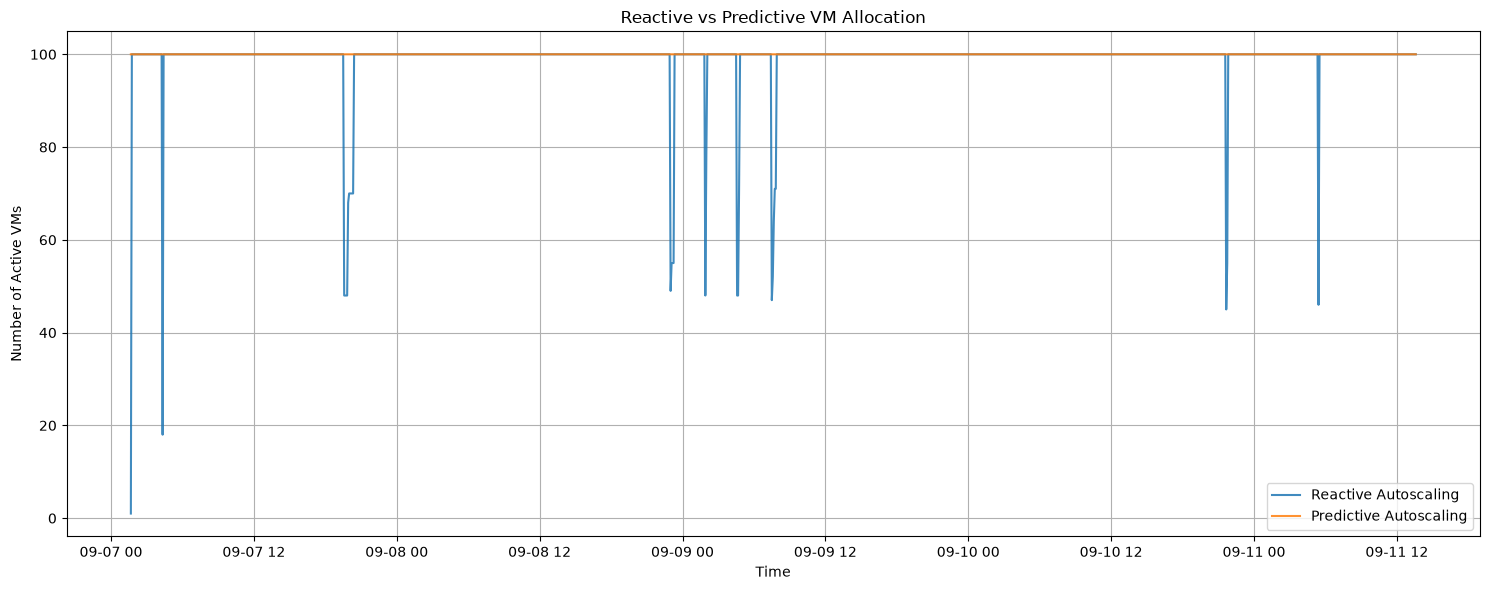

In [24]:
# Compare how many VMs each policy keeps running
plt.figure(figsize=(15, 6))

plt.plot(
    reactive_df.index,
    reactive_df["active_vm_count"],
    label="Reactive Autoscaling",
    alpha=0.85
)

plt.plot(
    predictive_df.index,
    predictive_df["active_vm_count"],
    label="Predictive Autoscaling",
    alpha=0.85
)

plt.title("Reactive vs Predictive VM Allocation")

plt.xlabel("Time")
plt.ylabel("Number of Active VMs")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
#Cell 9

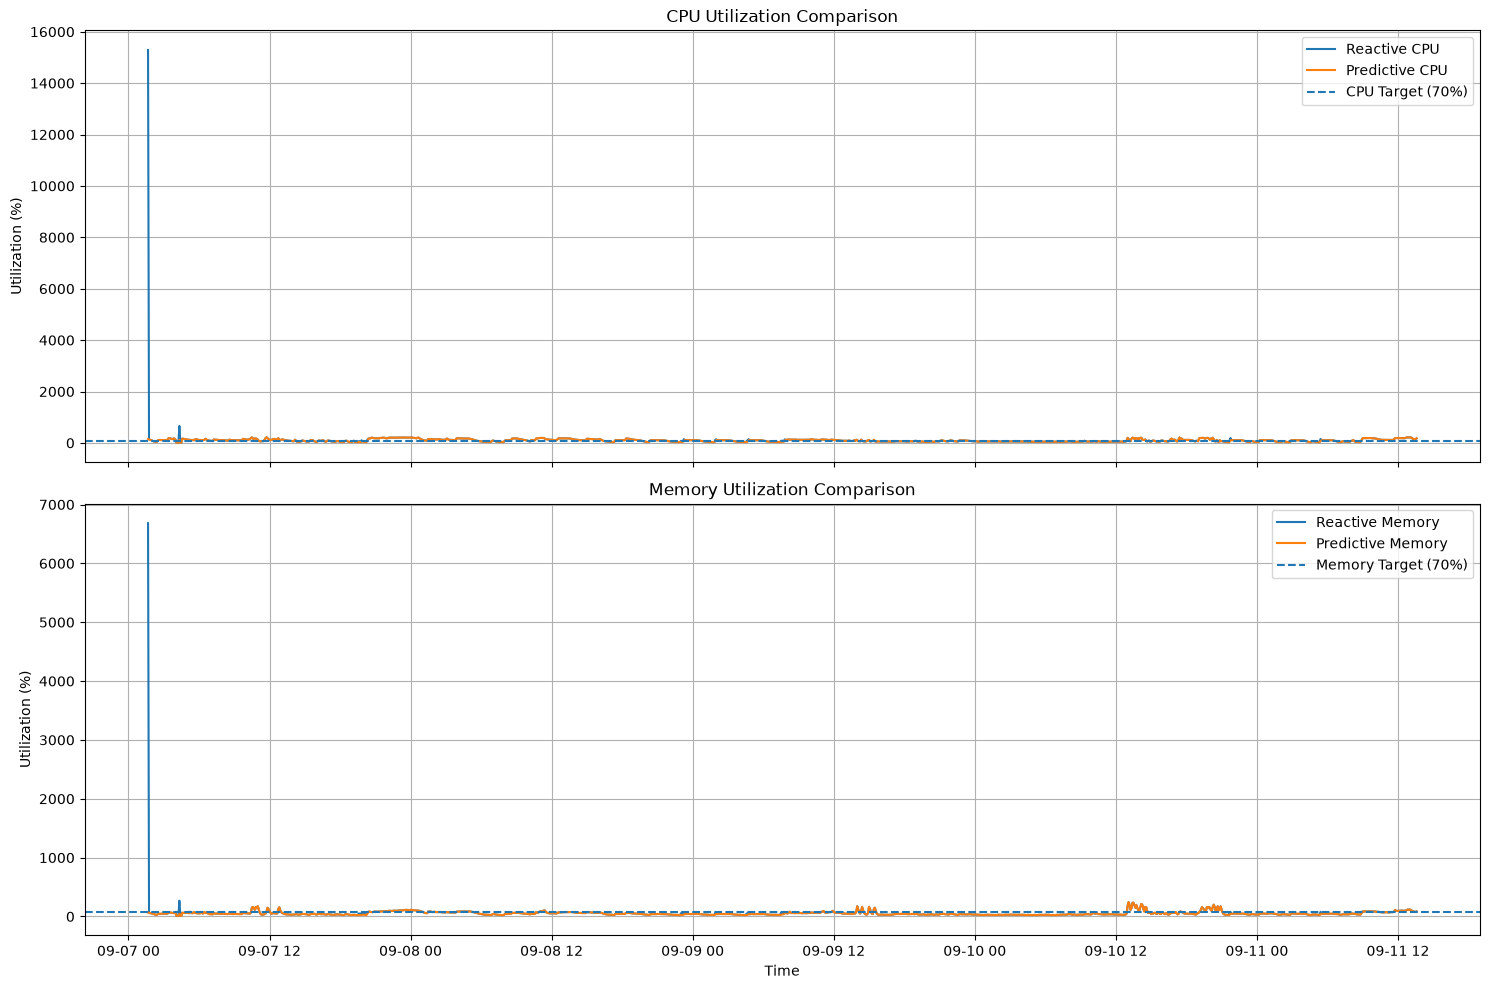

In [26]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 10),
    sharex=True
)

# Compare CPU utilization
axes[0].plot(
    reactive_df.index,
    reactive_df["cpu_utilization_pct"],
    label="Reactive CPU"
)

axes[0].plot(
    predictive_df.index,
    predictive_df["cpu_utilization_pct"],
    label="Predictive CPU"
)

axes[0].axhline(
    AUTOSCALING_CONFIG["cpu_target"] * 100,
    linestyle="--",
    label="CPU Target (70%)"
)

axes[0].set_title("CPU Utilization Comparison")
axes[0].set_ylabel("Utilization (%)")
axes[0].legend()
axes[0].grid(True)

# Compare memory utilization
axes[1].plot(
    reactive_df.index,
    reactive_df["memory_utilization_pct"],
    label="Reactive Memory"
)

axes[1].plot(
    predictive_df.index,
    predictive_df["memory_utilization_pct"],
    label="Predictive Memory"
)

axes[1].axhline(
    AUTOSCALING_CONFIG["memory_target"] * 100,
    linestyle="--",
    label="Memory Target (70%)"
)

axes[1].set_title("Memory Utilization Comparison")
axes[1].set_ylabel("Utilization (%)")
axes[1].set_xlabel("Time")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
#Cell 10

In [28]:
def calculate_policy_metrics(results, policy_name):

    return {

        "Policy": policy_name,

        "Average Active VMs": results[
            "active_vm_count"
        ].mean(),

        "Maximum Active VMs": results[
            "active_vm_count"
        ].max(),

        "Average CPU Utilization (%)": results[
            "cpu_utilization_pct"
        ].mean(),

        "Average Memory Utilization (%)": results[
            "memory_utilization_pct"
        ].mean(),

        "CPU Overload Intervals": results[
            "cpu_overload"
        ].sum(),

        "Memory Overload Intervals": results[
            "memory_overload"
        ].sum(),

        "Scale Up Events": (
            results["scaling_action"] == "scale_up"
        ).sum(),

        "Scale Down Events": (
            results["scaling_action"] == "scale_down"
        ).sum(),

        "Average Unused CPU (MHz)": results[
            "unused_cpu_capacity_mhz"
        ].mean(),

        "Average Unused Memory (KB)": results[
            "unused_memory_capacity_kb"
        ].mean()
    }


# Calculate the same performance measures for both strategies
reactive_metrics = calculate_policy_metrics(
    reactive_df,
    "Reactive"
)

predictive_metrics = calculate_policy_metrics(
    predictive_df,
    "Predictive"
)

phase6_summary = pd.DataFrame([
    reactive_metrics,
    predictive_metrics
])

print("Phase 6 Autoscaling Performance Summary:")

display(
    phase6_summary.round(2)
)

Phase 6 Autoscaling Performance Summary:


,Policy,Average Active VMs,Maximum Active VMs,Average CPU Utilization (%),Average Memory Utilization (%),CPU Overload Intervals,Memory Overload Intervals,Scale Up Events,Scale Down Events,Average Unused CPU (MHz),Average Unused Memory (KB)
0,Reactive,98.99,100,110.29,59.65,633,88,18,8,14275.28,5.057442e+08
1,Predictive,100.00,100,97.38,53.89,627,86,1,0,23290.17,5.171054e+08


In [29]:
#Cell 11

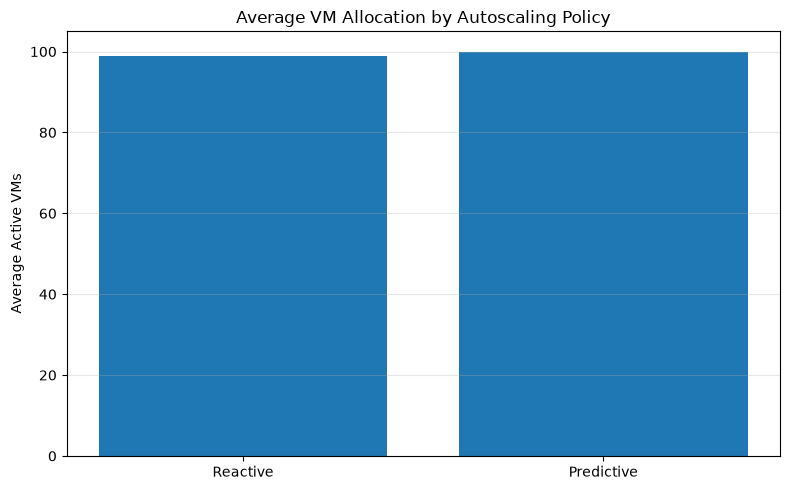

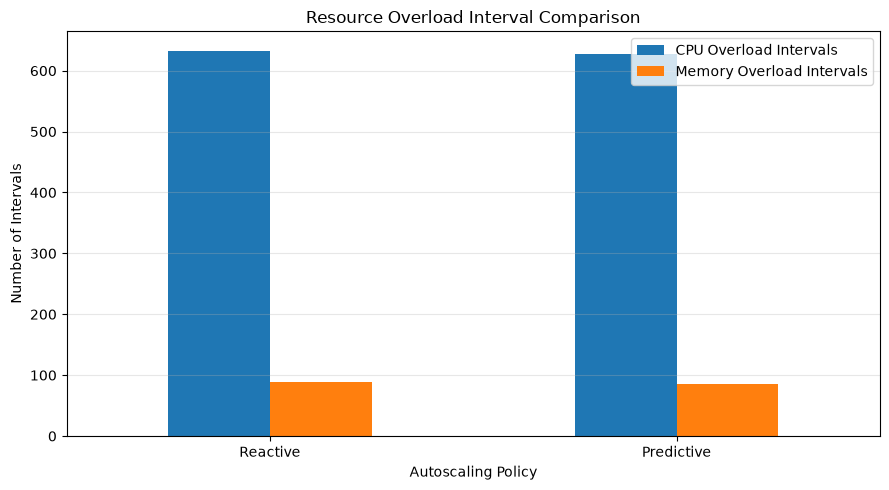

In [30]:
# Compare the average number of active VMs
plt.figure(figsize=(8, 5))

plt.bar(
    phase6_summary["Policy"],
    phase6_summary["Average Active VMs"]
)

plt.title("Average VM Allocation by Autoscaling Policy")
plt.ylabel("Average Active VMs")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Compare the number of overload intervals
overload_comparison = phase6_summary.set_index(
    "Policy"
)[
    [
        "CPU Overload Intervals",
        "Memory Overload Intervals"
    ]
]

overload_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Resource Overload Interval Comparison")
plt.ylabel("Number of Intervals")
plt.xlabel("Autoscaling Policy")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
#Cell 12

In [32]:
# Save the individual autoscaling results
reactive_df.to_csv(
    "phase6_reactive_autoscaling.csv"
)

predictive_df.to_csv(
    "phase6_predictive_autoscaling.csv"
)

# Save the comparison summary
phase6_summary.to_csv(
    "phase6_autoscaling_comparison.csv",
    index=False
)

print("Phase 6 results saved successfully.")

print("\nGenerated files:")
print("1. phase6_reactive_autoscaling.csv")
print("2. phase6_predictive_autoscaling.csv")
print("3. phase6_autoscaling_comparison.csv")

Phase 6 results saved successfully.

Generated files:
1. phase6_reactive_autoscaling.csv
2. phase6_predictive_autoscaling.csv
3. phase6_autoscaling_comparison.csv


In [35]:
#Phase 7
#Step 7.1

In [36]:
# Load the detailed results produced by both autoscaling strategies.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REACTIVE_FILE = "phase6_reactive_autoscaling.csv"
PREDICTIVE_FILE = "phase6_predictive_autoscaling.csv"

for file_path in [REACTIVE_FILE, PREDICTIVE_FILE]:
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"{file_path} was not found. Please run Phase 6 first."
        )

reactive_df = pd.read_csv(REACTIVE_FILE)
predictive_df = pd.read_csv(PREDICTIVE_FILE)

print("Reactive autoscaling columns:")
print(reactive_df.columns.tolist())

print("\nPredictive autoscaling columns:")
print(predictive_df.columns.tolist())

print("\nReactive results preview:")
display(reactive_df.head())

print("\nPredictive results preview:")
display(predictive_df.head())

Reactive autoscaling columns:
['timestamp', 'policy', 'previous_vm_count', 'desired_vm_count', 'active_vm_count', 'scaling_action', 'actual_cpu_demand_mhz', 'actual_memory_demand_kb', 'cpu_utilization_pct', 'memory_utilization_pct', 'total_cpu_capacity_mhz', 'total_memory_capacity_kb', 'unused_cpu_capacity_mhz', 'unused_memory_capacity_kb', 'cpu_overload', 'memory_overload']

Predictive autoscaling columns:
['timestamp', 'policy', 'previous_vm_count', 'desired_vm_count', 'active_vm_count', 'scaling_action', 'actual_cpu_demand_mhz', 'actual_memory_demand_kb', 'cpu_utilization_pct', 'memory_utilization_pct', 'total_cpu_capacity_mhz', 'total_memory_capacity_kb', 'unused_cpu_capacity_mhz', 'unused_memory_capacity_kb', 'cpu_overload', 'memory_overload']

Reactive results preview:


,timestamp,policy,previous_vm_count,desired_vm_count,active_vm_count,scaling_action,actual_cpu_demand_mhz,actual_memory_demand_kb,cpu_utilization_pct,memory_utilization_pct,total_cpu_capacity_mhz,total_memory_capacity_kb,unused_cpu_capacity_mhz,unused_memory_capacity_kb,cpu_overload,memory_overload
0,2013-09-07 01:40:00+00:00,Reactive,1,0,1,no_change,1.360624e+06,7.494963e+08,15291.056576,6683.474763,8898.169486,1.121417e+07,-1.351726e+06,-7.382821e+08,True,True
1,2013-09-07 01:45:00+00:00,Reactive,1,100,100,scale_up,1.193943e+06,6.850305e+08,134.178440,61.086153,889816.948592,1.121417e+09,-3.041256e+05,4.363865e+08,True,False
2,2013-09-07 01:50:00+00:00,Reactive,100,100,100,no_change,1.094531e+06,6.373771e+08,123.006308,56.836756,889816.948592,1.121417e+09,-2.047140e+05,4.840400e+08,True,False
3,2013-09-07 01:55:00+00:00,Reactive,100,100,100,no_change,1.000821e+06,6.142636e+08,112.474928,54.775658,889816.948592,1.121417e+09,-1.110040e+05,5.071535e+08,True,False
4,2013-09-07 02:00:00+00:00,Reactive,100,100,100,no_change,8.374864e+05,5.870016e+08,94.118956,52.344630,889816.948592,1.121417e+09,5.233053e+04,5.344154e+08,False,False



Predictive results preview:


,timestamp,policy,previous_vm_count,desired_vm_count,active_vm_count,scaling_action,actual_cpu_demand_mhz,actual_memory_demand_kb,cpu_utilization_pct,memory_utilization_pct,total_cpu_capacity_mhz,total_memory_capacity_kb,unused_cpu_capacity_mhz,unused_memory_capacity_kb,cpu_overload,memory_overload
0,2013-09-07 01:40:00+00:00,Predictive,1,100,100,scale_up,1.360624e+06,7.494963e+08,152.910566,66.834748,889816.948592,1.121417e+09,-470807.181720,3.719208e+08,True,False
1,2013-09-07 01:45:00+00:00,Predictive,100,100,100,no_change,1.193943e+06,6.850305e+08,134.178440,61.086153,889816.948592,1.121417e+09,-304125.552235,4.363865e+08,True,False
2,2013-09-07 01:50:00+00:00,Predictive,100,100,100,no_change,1.094531e+06,6.373771e+08,123.006308,56.836756,889816.948592,1.121417e+09,-204714.025841,4.840400e+08,True,False
3,2013-09-07 01:55:00+00:00,Predictive,100,100,100,no_change,1.000821e+06,6.142636e+08,112.474928,54.775658,889816.948592,1.121417e+09,-111004.026508,5.071535e+08,True,False
4,2013-09-07 02:00:00+00:00,Predictive,100,100,100,no_change,8.374864e+05,5.870016e+08,94.118956,52.344630,889816.948592,1.121417e+09,52330.529269,5.344154e+08,False,False


In [37]:
#Step 7.2

In [38]:
# Define the assumptions used to estimate energy consumption and cost.

ENERGY_CONFIG = {
    "idle_power_watts": 100,
    "maximum_power_watts": 200,
    "pue": 1.5,
    "electricity_rate_per_kwh": 8.0,
    "vm_cost_per_hour": 5.0,
    "interval_minutes": 5
}

print("Energy and cost configuration:")
for key, value in ENERGY_CONFIG.items():
    print(f"{key}: {value}")

Energy and cost configuration:
idle_power_watts: 100
maximum_power_watts: 200
pue: 1.5
electricity_rate_per_kwh: 8.0
vm_cost_per_hour: 5.0
interval_minutes: 5


In [39]:
#Step 7.3

In [40]:
# Find the required columns even if their names differ slightly.

def find_column(df, possible_names):
    for name in possible_names:
        if name in df.columns:
            return name
    return None


def prepare_energy_data(df, policy_name):

    data = df.copy()

    vm_col = find_column(data, [
        "active_vms",
        "active_vm_count",
        "active_vm",
        "running_vms",
        "current_vms"
    ])

    cpu_util_col = find_column(data, [
        "cpu_utilization_percent",
        "cpu_utilization",
        "cpu_utilization_pct",
        "actual_cpu_utilization"
    ])

    cpu_usage_col = find_column(data, [
        "actual_cpu_usage_mhz",
        "actual_cpu_demand_mhz",
        "cpu_usage_mhz",
        "actual_cpu"
    ])

    cpu_capacity_col = find_column(data, [
        "total_cpu_capacity_mhz",
        "cpu_capacity_mhz",
        "allocated_cpu_capacity_mhz"
    ])

    if vm_col is None:
        raise ValueError(
            f"{policy_name}: Active VM column not found. "
            f"Available columns: {data.columns.tolist()}"
        )

    # Use recorded CPU utilization when available.
    if cpu_util_col is not None:
        cpu_util = pd.to_numeric(
            data[cpu_util_col], errors="coerce"
        )

        # Convert fractional utilization to percentage if needed.
        if cpu_util.dropna().max() <= 1.5:
            cpu_util = cpu_util * 100

    # Otherwise calculate utilization from CPU usage and capacity.
    elif cpu_usage_col and cpu_capacity_col:
        cpu_usage = pd.to_numeric(
            data[cpu_usage_col], errors="coerce"
        )
        cpu_capacity = pd.to_numeric(
            data[cpu_capacity_col], errors="coerce"
        )

        cpu_util = (
            cpu_usage / cpu_capacity.replace(0, np.nan)
        ) * 100

    else:
        raise ValueError(
            f"{policy_name}: Could not find CPU utilization or "
            "the CPU usage and capacity columns."
        )

    result = pd.DataFrame({
        "active_vms": pd.to_numeric(
            data[vm_col], errors="coerce"
        ),
        "cpu_utilization_percent": cpu_util
    })

    result = result.replace([np.inf, -np.inf], np.nan)
    result = result.dropna()

    result["active_vms"] = result["active_vms"].clip(lower=0)

    print(
        f"{policy_name}: {len(result)} valid intervals prepared."
    )

    return result


reactive_energy_data = prepare_energy_data(
    reactive_df, "Reactive"
)

predictive_energy_data = prepare_energy_data(
    predictive_df, "Predictive"
)

display(reactive_energy_data.head())

Reactive: 1296 valid intervals prepared.
Predictive: 1296 valid intervals prepared.


,active_vms,cpu_utilization_percent
0,1,15291.056576
1,100,134.178440
2,100,123.006308
3,100,112.474928
4,100,94.118956


In [41]:
#Step 7.4

In [42]:
# Estimate energy consumption and operating cost for each interval.

def calculate_energy_and_cost(data, policy_name):

    result = data.copy()

    idle_power = ENERGY_CONFIG["idle_power_watts"]
    max_power = ENERGY_CONFIG["maximum_power_watts"]
    pue = ENERGY_CONFIG["pue"]

    interval_hours = (
        ENERGY_CONFIG["interval_minutes"] / 60
    )

    electricity_rate = (
        ENERGY_CONFIG["electricity_rate_per_kwh"]
    )

    vm_hourly_rate = ENERGY_CONFIG["vm_cost_per_hour"]

    # Limit CPU utilization to the physical range for power estimation.
    cpu_load = (
        result["cpu_utilization_percent"]
        .clip(lower=0, upper=100) / 100
    )

    # Estimate the power consumed by one VM.
    result["power_per_vm_watts"] = (
        idle_power + (max_power - idle_power) * cpu_load
    )

    # Estimate total server power, including data-centre overhead.
    result["total_power_watts"] = (
        result["active_vms"]
        * result["power_per_vm_watts"]
        * pue
    )

    # Convert power into energy for each simulation interval.
    result["energy_kwh"] = (
        result["total_power_watts"]
        * interval_hours / 1000
    )

    # Estimate electricity cost.
    result["electricity_cost"] = (
        result["energy_kwh"] * electricity_rate
    )

    # Estimate VM operating cost based on VM-hours.
    result["vm_hours"] = (
        result["active_vms"] * interval_hours
    )

    result["vm_operating_cost"] = (
        result["vm_hours"] * vm_hourly_rate
    )

    # Combined estimated cost.
    result["total_estimated_cost"] = (
        result["electricity_cost"]
        + result["vm_operating_cost"]
    )

    result["policy"] = policy_name

    return result


reactive_energy_results = calculate_energy_and_cost(
    reactive_energy_data, "Reactive"
)

predictive_energy_results = calculate_energy_and_cost(
    predictive_energy_data, "Predictive"
)

print("Energy and cost calculations completed.")
display(reactive_energy_results.head())

Energy and cost calculations completed.


,active_vms,cpu_utilization_percent,power_per_vm_watts,total_power_watts,energy_kwh,electricity_cost,vm_hours,vm_operating_cost,total_estimated_cost,policy
0,1,15291.056576,200.000000,300.000000,0.025000,0.200000,0.083333,0.416667,0.616667,Reactive
1,100,134.178440,200.000000,30000.000000,2.500000,20.000000,8.333333,41.666667,61.666667,Reactive
2,100,123.006308,200.000000,30000.000000,2.500000,20.000000,8.333333,41.666667,61.666667,Reactive
3,100,112.474928,200.000000,30000.000000,2.500000,20.000000,8.333333,41.666667,61.666667,Reactive
4,100,94.118956,194.118956,29117.843349,2.426487,19.411896,8.333333,41.666667,61.078562,Reactive


In [45]:
#Step 7.5
#Cell 5 — Generate the comparison summary

In [46]:
# Summarize total energy consumption and estimated operating costs.

def create_energy_summary(results):

    return {
        "Total Energy (kWh)": results["energy_kwh"].sum(),
        "Electricity Cost (₹)": results["electricity_cost"].sum(),
        "VM Operating Cost (₹)": results["vm_operating_cost"].sum(),
        "Total Estimated Cost (₹)": results["total_estimated_cost"].sum(),
        "Average Active VMs": results["active_vms"].mean(),
        "Average Power (W)": results["total_power_watts"].mean(),
        "Simulation Intervals": len(results)
    }


energy_summary = pd.DataFrame({
    "Reactive": create_energy_summary(
        reactive_energy_results
    ),
    "Predictive": create_energy_summary(
        predictive_energy_results
    )
}).T

print("Phase 7: Energy and Cost Comparison")

display(energy_summary.round(3))

Phase 7: Energy and Cost Comparison


,Total Energy (kWh),Electricity Cost (₹),VM Operating Cost (₹),Total Estimated Cost (₹),Average Active VMs,Average Power (W),Simulation Intervals
Reactive,2873.931,22991.446,53452.917,76444.363,98.987,26610.470,1296.0
Predictive,2895.177,23161.417,54000.000,77161.417,100.000,26807.196,1296.0


In [47]:
#Cell 6 — Calculate predictive savings

In [48]:
# Calculate the percentage difference between the two policies.

reactive_energy = energy_summary.loc[
    "Reactive", "Total Energy (kWh)"
]

predictive_energy = energy_summary.loc[
    "Predictive", "Total Energy (kWh)"
]

reactive_cost = energy_summary.loc[
    "Reactive", "Total Estimated Cost (₹)"
]

predictive_cost = energy_summary.loc[
    "Predictive", "Total Estimated Cost (₹)"
]


energy_savings_percent = (
    (reactive_energy - predictive_energy)
    / reactive_energy * 100
    if reactive_energy > 0 else 0
)

cost_savings_percent = (
    (reactive_cost - predictive_cost)
    / reactive_cost * 100
    if reactive_cost > 0 else 0
)

print(f"Energy savings: {energy_savings_percent:.2f}%")
print(f"Estimated cost savings: {cost_savings_percent:.2f}%")

if energy_savings_percent > 0:
    print("Predictive autoscaling consumed less estimated energy.")
elif energy_savings_percent < 0:
    print("Reactive autoscaling consumed less estimated energy.")
else:
    print("Both policies consumed the same estimated energy.")

if cost_savings_percent > 0:
    print("Predictive autoscaling had a lower estimated cost.")
elif cost_savings_percent < 0:
    print("Reactive autoscaling had a lower estimated cost.")
else:
    print("Both policies had the same estimated cost.")

Energy savings: -0.74%
Estimated cost savings: -0.94%
Reactive autoscaling consumed less estimated energy.
Reactive autoscaling had a lower estimated cost.


In [49]:
#Step 7.6 — Visualize the results
# Cell 7 — Energy and cost comparison charts

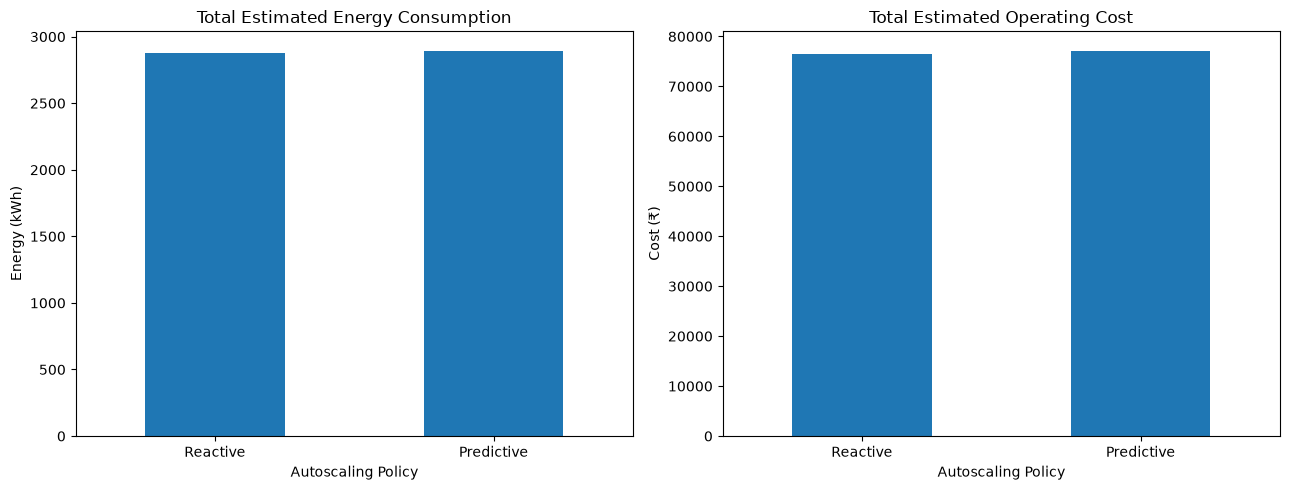

In [50]:
# Compare estimated energy consumption and operating cost.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

energy_summary["Total Energy (kWh)"].plot(
    kind="bar",
    ax=axes[0],
    title="Total Estimated Energy Consumption"
)

axes[0].set_ylabel("Energy (kWh)")
axes[0].set_xlabel("Autoscaling Policy")
axes[0].tick_params(axis="x", rotation=0)

energy_summary["Total Estimated Cost (₹)"].plot(
    kind="bar",
    ax=axes[1],
    title="Total Estimated Operating Cost"
)

axes[1].set_ylabel("Cost (₹)")
axes[1].set_xlabel("Autoscaling Policy")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [52]:
# Cell 8 — Save Phase 7 results

In [53]:
# Save the detailed calculations and comparison summary.

reactive_energy_results.to_csv(
    "phase7_reactive_energy_cost.csv",
    index=False
)

predictive_energy_results.to_csv(
    "phase7_predictive_energy_cost.csv",
    index=False
)

energy_summary.to_csv(
    "phase7_energy_cost_comparison.csv"
)

print("Phase 7 results saved successfully.")

print("1. phase7_reactive_energy_cost.csv")
print("2. phase7_predictive_energy_cost.csv")
print("3. phase7_energy_cost_comparison.csv")

Phase 7 results saved successfully.
1. phase7_reactive_energy_cost.csv
2. phase7_predictive_energy_cost.csv
3. phase7_energy_cost_comparison.csv


In [54]:
# Phase 8 — Final Evaluation, Results, and Project Conclusion

In [55]:
# Step 8.1 — Check that all phase outputs are available
# Run this first. It checks for the files generated in earlier phases and tells us if anything is missing.

# Cell 1 — Check project output files

In [56]:
# Check that the main output files from Phases 4 to 7 are available.

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

required_files = [
    "phase4_final_test_results.csv",
    "phase5_cloud_simulation_results.csv",
    "phase6_reactive_autoscaling.csv",
    "phase6_predictive_autoscaling.csv",
    "phase6_autoscaling_comparison.csv",
    "phase7_reactive_energy_cost.csv",
    "phase7_predictive_energy_cost.csv",
    "phase7_energy_cost_comparison.csv"
]

available_files = []
missing_files = []

for file_name in required_files:
    if os.path.exists(file_name):
        available_files.append(file_name)
        print("FOUND:", file_name)
    else:
        missing_files.append(file_name)
        print("MISSING:", file_name)

print("\nAvailable files:", len(available_files))
print("Missing files:", len(missing_files))

if missing_files:
    print("\nPlease check these missing files before continuing.")
else:
    print("\nAll expected Phase 4–7 output files are available.")

FOUND: phase4_final_test_results.csv
MISSING: phase5_cloud_simulation_results.csv
FOUND: phase6_reactive_autoscaling.csv
FOUND: phase6_predictive_autoscaling.csv
FOUND: phase6_autoscaling_comparison.csv
FOUND: phase7_reactive_energy_cost.csv
FOUND: phase7_predictive_energy_cost.csv
FOUND: phase7_energy_cost_comparison.csv

Available files: 7
Missing files: 1

Please check these missing files before continuing.


In [57]:
# Step 8.2 — Load and inspect the final results
# Cell 2 — Load Phase 4–7 outputs

In [60]:
# Load the outputs required for final project evaluation.
# Phase 5 is optional because the final comparison uses Phase 6 and 7.

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Phase 4 model evaluation
phase4_results = pd.read_csv(
    "phase4_final_test_results.csv"
)

# Load Phase 5 only if the file exists
if os.path.exists("phase5_cloud_simulation_results.csv"):

    phase5_results = pd.read_csv(
        "phase5_cloud_simulation_results.csv"
    )

    print("Phase 5 results loaded successfully.")

else:

    phase5_results = None

    print(
        "Phase 5 CSV not found. "
        "Continuing with Phase 6 and Phase 7 results."
    )

# Load Phase 6 results
phase6_reactive = pd.read_csv(
    "phase6_reactive_autoscaling.csv"
)

phase6_predictive = pd.read_csv(
    "phase6_predictive_autoscaling.csv"
)

phase6_comparison = pd.read_csv(
    "phase6_autoscaling_comparison.csv"
)

# Load Phase 7 results
phase7_reactive = pd.read_csv(
    "phase7_reactive_energy_cost.csv"
)

phase7_predictive = pd.read_csv(
    "phase7_predictive_energy_cost.csv"
)

phase7_comparison = pd.read_csv(
    "phase7_energy_cost_comparison.csv"
)

print("\nAll essential project results loaded.")

print("\nPhase 4 model results:")
display(phase4_results.head())

print("\nPhase 6 comparison:")
display(phase6_comparison)

print("\nPhase 7 comparison:")
display(phase7_comparison)

Phase 5 CSV not found. Continuing with Phase 6 and Phase 7 results.

All essential project results loaded.

Phase 4 model results:


,Target,Selected Model,Test MAE,Test RMSE,Test R2
0,target_cpu_usage_mhz,Random Forest,1.081033e+05,1.695096e+05,0.843432
1,target_memory_usage_kb,Linear Regression,6.080312e+07,1.289318e+08,0.854878



Phase 6 comparison:


,Policy,Average Active VMs,Maximum Active VMs,Average CPU Utilization (%),Average Memory Utilization (%),CPU Overload Intervals,Memory Overload Intervals,Scale Up Events,Scale Down Events,Average Unused CPU (MHz),Average Unused Memory (KB)
0,Reactive,98.986883,100,110.290486,59.649904,633,88,18,8,14275.276723,5.057442e+08
1,Predictive,100.000000,100,97.382589,53.888213,627,86,1,0,23290.166024,5.171054e+08



Phase 7 comparison:


,Unnamed: 0,Total Energy (kWh),Electricity Cost (₹),VM Operating Cost (₹),Total Estimated Cost (₹),Average Active VMs,Average Power (W),Simulation Intervals
0,Reactive,2873.930773,22991.446180,53452.916667,76444.362847,98.986883,26610.470116,1296.0
1,Predictive,2895.177124,23161.416994,54000.000000,77161.416994,100.000000,26807.195595,1296.0


In [61]:
# Cell 3 — Final comparison table

In [62]:
# Combine the Phase 6 autoscaling results and Phase 7 energy results.
# Reactive autoscaling is used as the baseline for comparison.

final_comparison = pd.DataFrame({
    "Metric": [
        "Average active VMs",
        "Maximum active VMs",
        "Average CPU utilization (%)",
        "Average memory utilization (%)",
        "CPU overload intervals",
        "Memory overload intervals",
        "Scale-up events",
        "Scale-down events",
        "Total energy (kWh)",
        "Electricity cost (INR)",
        "VM operating cost (INR)",
        "Total estimated cost (INR)"
    ],

    "Reactive": [
        98.987,
        100,
        110.29,
        59.65,
        633,
        88,
        18,
        8,
        2873.931,
        22991.446,
        53452.917,
        76444.363
    ],

    "Predictive": [
        100.000,
        100,
        97.38,
        53.89,
        627,
        86,
        1,
        0,
        2895.177,
        23161.417,
        54000.000,
        77161.417
    ]
})

# Calculate the difference between the two approaches.
final_comparison["Difference (Predictive - Reactive)"] = (
    final_comparison["Predictive"]
    - final_comparison["Reactive"]
)

print("PHASE 8: FINAL EXPERIMENTAL COMPARISON")

display(final_comparison.round(3))

PHASE 8: FINAL EXPERIMENTAL COMPARISON


,Metric,Reactive,Predictive,Difference (Predictive - Reactive)
0,Average active VMs,98.987,100.000,1.013
1,Maximum active VMs,100.000,100.000,0.000
2,Average CPU utilization (%),110.290,97.380,-12.910
3,Average memory utilization (%),59.650,53.890,-5.760
4,CPU overload intervals,633.000,627.000,-6.000
5,Memory overload intervals,88.000,86.000,-2.000
6,Scale-up events,18.000,1.000,-17.000
7,Scale-down events,8.000,0.000,-8.000
8,Total energy (kWh),2873.931,2895.177,21.246
9,Electricity cost (INR),22991.446,23161.417,169.971


In [63]:
# Cell 4 — Calculate final energy and cost differences

In [64]:
# Compare predictive autoscaling against reactive autoscaling.

reactive_energy = 2873.931
predictive_energy = 2895.177

reactive_cost = 76444.363
predictive_cost = 77161.417

energy_difference_percent = (
    (predictive_energy - reactive_energy)
    / reactive_energy * 100
)

cost_difference_percent = (
    (predictive_cost - reactive_cost)
    / reactive_cost * 100
)

print("FINAL ENERGY AND COST EVALUATION")
print("--------------------------------")

print(
    f"Energy difference: {energy_difference_percent:.2f}%"
)

print(
    f"Cost difference: {cost_difference_percent:.2f}%"
)

print("\nInterpretation:")

if energy_difference_percent < 0:
    print("Predictive autoscaling reduced energy consumption.")
else:
    print("Reactive autoscaling consumed less estimated energy.")

if cost_difference_percent < 0:
    print("Predictive autoscaling reduced operating cost.")
else:
    print("Reactive autoscaling had a lower estimated operating cost.")

FINAL ENERGY AND COST EVALUATION
--------------------------------
Energy difference: 0.74%
Cost difference: 0.94%

Interpretation:
Reactive autoscaling consumed less estimated energy.
Reactive autoscaling had a lower estimated operating cost.


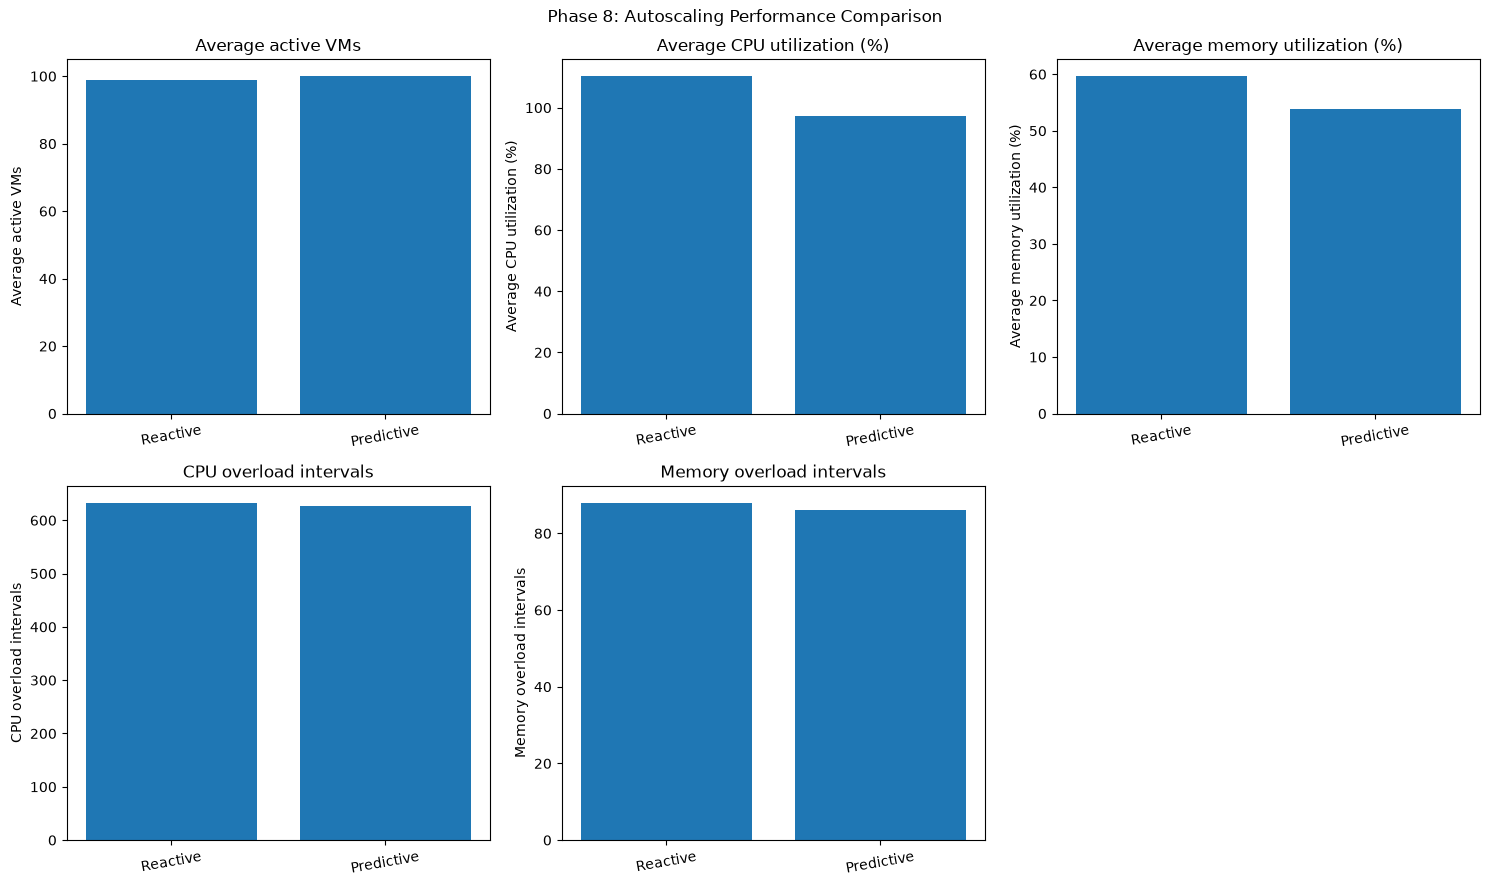

In [65]:
# Compare the major performance indicators of both autoscaling policies.

metrics = [
    ("Average active VMs", 98.987, 100.000),
    ("Average CPU utilization (%)", 110.29, 97.38),
    ("Average memory utilization (%)", 59.65, 53.89),
    ("CPU overload intervals", 633, 627),
    ("Memory overload intervals", 88, 86)
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (metric, reactive_value, predictive_value) in enumerate(metrics):
    axes[i].bar(
        ["Reactive", "Predictive"],
        [reactive_value, predictive_value]
    )
    axes[i].set_title(metric)
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis="x", rotation=10)

axes[-1].axis("off")

plt.suptitle("Phase 8: Autoscaling Performance Comparison")
plt.tight_layout()

plt.savefig(
    "phase8_autoscaling_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

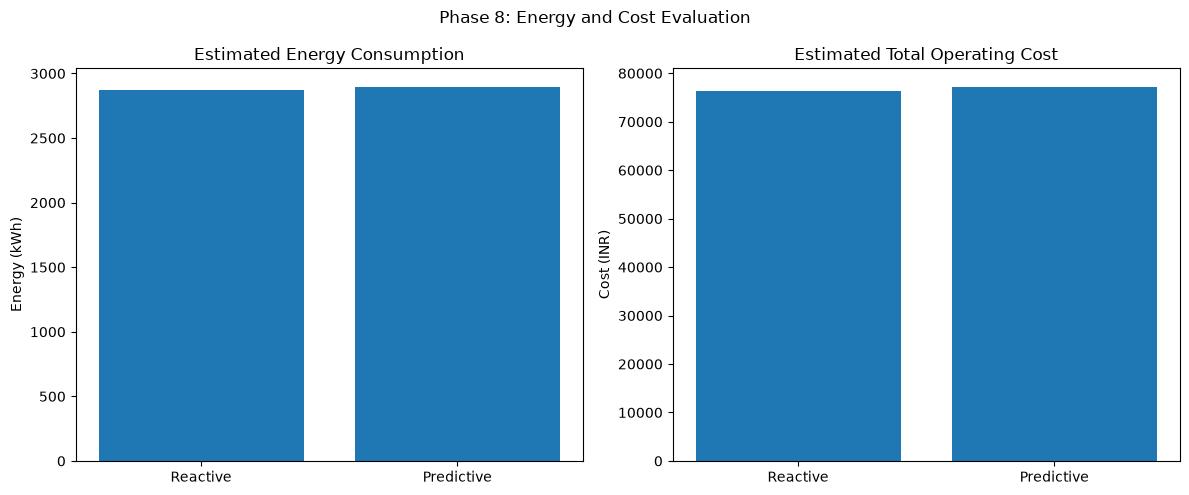

In [66]:
# Compare estimated energy consumption and total operating cost.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    ["Reactive", "Predictive"],
    [reactive_energy, predictive_energy]
)

axes[0].set_title("Estimated Energy Consumption")
axes[0].set_ylabel("Energy (kWh)")

axes[1].bar(
    ["Reactive", "Predictive"],
    [reactive_cost, predictive_cost]
)

axes[1].set_title("Estimated Total Operating Cost")
axes[1].set_ylabel("Cost (INR)")

plt.suptitle("Phase 8: Energy and Cost Evaluation")
plt.tight_layout()

plt.savefig(
    "phase8_energy_cost_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
# Save the final experimental comparison and summary.

final_comparison.to_csv(
    "phase8_final_experimental_comparison.csv",
    index=False
)

energy_cost_summary = pd.DataFrame({
    "Policy": ["Reactive", "Predictive"],
    "Energy_kWh": [reactive_energy, predictive_energy],
    "Estimated_Cost_INR": [reactive_cost, predictive_cost],
    "Average_Active_VMs": [98.987, 100.000],
    "Energy_Difference_Percent": [0, energy_difference_percent],
    "Cost_Difference_Percent": [0, cost_difference_percent]
})

energy_cost_summary.to_csv(
    "phase8_final_energy_cost_summary.csv",
    index=False
)

print("Final comparison files saved successfully.")

Final comparison files saved successfully.
